# SUNSHIELD v2 — Notebook 5: Plots & Final Files

Input: `step3_outputs` (Notebook 3) and `step4_outputs` (Notebook 4).
Main version: A (plain 0/1), best k on Training (from Notebook 4).
Output: plots 1–8, the six final files and the summary tables, zipped into `final_outputs.zip`.

The plots are the same as before. Changes: the physical expected power is drawn as a thin dashed line,
Plot 2 shows the new rule (deviation from expected power with μ ± k·σ), Plot 6 shows the new workflow, and
**Plot 8 (new)** repeats the example days of the previous report (outages on 8–9 June, cloudy morning on 11 June).

In [1]:
# Cell 1 — Libraries and inputs
import os, re, zipfile, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def find_root():
    for d in ['.', '..', '../..']:
        if os.path.exists(os.path.join(d, 'data', 'raw', 'Plant_1_Generation_Data.csv')):
            return os.path.abspath(d)
    return os.path.abspath('.')

ROOT = find_root()
OUTPUTS = os.path.join(ROOT, 'outputs')

def get_step(name):
    folder = os.path.join(OUTPUTS, name)
    if not os.path.isdir(folder):
        zip_path = os.path.join(OUTPUTS, name + '.zip') if os.path.exists(os.path.join(OUTPUTS, name + '.zip')) else name + '.zip'
        if not os.path.exists(zip_path):
            from google.colab import files
            print(f'Upload {name}.zip'); uploaded = files.upload(); zip_path = list(uploaded)[0]
        shutil.unpack_archive(zip_path, folder, 'zip')
    return folder

STEP3_DIR, STEP4_DIR = get_step('step3_outputs'), get_step('step4_outputs')
print('Notebook 3 files:', sorted(os.listdir(STEP3_DIR)))
print('Notebook 4 files:', sorted(os.listdir(STEP4_DIR)))

Notebook 3 files: ['limits_mu_sigma.csv', 'test_with_anomalies.csv', 'train_with_anomalies.csv', 'val_with_anomalies.csv']
Notebook 4 files: ['A_plain', 'B_direction', 'experiments']


In [2]:
# Cell 2 — Settings (must match Notebooks 3 and 4)
K_VALUES    = [1.0, 1.5, 2.0, 2.5, 3.0]
MAIN        = 'A'           # main version: 'A' = plain 0/1, 'B' = below/above must match
SPLITS      = ['train', 'val', 'test']
NAMES       = {'train': 'Training', 'val': 'Validation', 'test': 'Testing'}
VERSION_DIR = {'A': 'A_plain', 'B': 'B_direction'}
VERSION_TXT = {'A': 'Version A (plain 0/1)', 'B': 'Version B (below/above must match)'}

OUT_DIR   = os.path.join(OUTPUTS, 'step5_outputs')
PLOT_DIR  = os.path.join(OUT_DIR, 'plots')
FINAL_DIR = os.path.join(OUT_DIR, 'final_files')
os.makedirs(PLOT_DIR, exist_ok=True)
os.makedirs(FINAL_DIR, exist_ok=True)

# Colors used in every plot
C_ACT, C_PRED, C_PHYS, C_OLD = '#1f77b4', '#ff7f0e', '#7f7f7f', '#c9a227'   # actual, LSTM, PVWatts, LSTM all-data
C_RES = {'TP': '#2ca02c', 'FP': '#d62728', 'FN': '#7f7f7f', 'Wrong direction': '#9467bd'}
def time_axis(ax):
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b\n%H:%M'))

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 10})

BEST_K = {}
for v, folder in VERSION_DIR.items():
    with open(os.path.join(STEP4_DIR, folder, 'best_k.txt')) as f:
        BEST_K[v] = float(re.findall(r'[\d.]+', f.read())[0])
limits = pd.read_csv(os.path.join(STEP3_DIR, 'limits_mu_sigma.csv'), index_col='SOURCE_KEY')
print('Best k from Notebook 4:', BEST_K, '| main version:', MAIN)

Best k from Notebook 4: {'A': 3.0, 'B': 3.0} | main version: A


In [3]:
# Cell 3 — Load the anomaly columns and add the result column (same rules as Notebook 4)
data = {}
for s in SPLITS:
    df = pd.read_csv(os.path.join(STEP3_DIR, f'{s}_with_anomalies.csv'), parse_dates=['DATE_TIME'])
    df = df.sort_values(['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True)
    df['actual_dir'] = np.sign(df['RESID_ACTUAL_kW']).astype(int)     # -1 below expected, +1 above
    df['pred_dir'] = np.sign(df['RESID_PRED_kW']).astype(int)
    data[s] = df

def result_column(df, k, version, line='pred'):
    """TP / FP / FN / TN / Wrong direction for every reading; 'not evaluated' below 0.2 kW/m²."""
    a = df[f'actual_anomaly_k{k}'].values
    p = df[f'{line}_anomaly_k{k}'].values
    if version == 'B':
        a, p = a * df['actual_dir'].values, p * np.sign(df[f'RESID_{line.upper()}_kW']).astype(int).values
    res = np.select([(a != 0) & (p == a), (a != 0) & (p != 0), a != 0, p != 0],
                    ['TP', 'Wrong direction', 'FN', 'FP'], 'TN')
    return np.where(df['EVALUATED'].values == 1, res, 'not evaluated')

def scores(res):
    tp, fp, fn, wd = [(res == x).sum() for x in ['TP', 'FP', 'FN', 'Wrong direction']]
    P = tp / (tp + fp + wd) if tp + fp + wd else 0.0
    R = tp / (tp + fn + wd) if tp + fn + wd else 0.0
    F = 2 * P * R / (P + R) if P + R else 0.0
    return P, R, F

# Check: the numbers must be the same as Notebook 4 (results_best_k.csv)
for v in VERSION_DIR:
    nb4 = pd.read_csv(os.path.join(STEP4_DIR, VERSION_DIR[v], 'results_best_k.csv'))
    for s in SPLITS:
        F = scores(result_column(data[s], BEST_K[v], v))[2]
        F_nb4 = nb4.loc[nb4['Split'] == NAMES[s], 'F1'].iloc[0]
        assert abs(F - F_nb4) < 1e-3, (v, s, F, F_nb4)
print('Same F1 as Notebook 4 for both versions and all splits.')
print({s: len(d) for s, d in data.items()})

Same F1 as Notebook 4 for both versions and all splits.
{'train': 36491, 'val': 11968, 'test': 10758}


In [4]:
# Cell 4 — Choose the example inverters and 2 days for the plots (same rule as before)
#   the inverter with the most actual anomalies at the best k, and its busiest day + the next day
K = BEST_K[MAIN]
PLANTS = sorted(data['train']['PLANT_ID'].unique())

def pick_example(df, k):
    col = f'actual_anomaly_k{k}'
    inv = df.groupby('SOURCE_KEY')[col].sum().idxmax()
    d = df[df['SOURCE_KEY'] == inv]
    day = d.groupby(d['DATE_TIME'].dt.normalize())[col].sum().idxmax()
    days = sorted(d['DATE_TIME'].dt.normalize().unique())
    i = days.index(day)
    start = days[max(0, min(i, len(days) - 2))]
    return inv, start, start + pd.Timedelta(days=2)

def window(df, inv, start, end):
    """Rows of one inverter between start and end, on a full 15-min grid so nights show as gaps."""
    d = df[(df['SOURCE_KEY'] == inv) & (df['DATE_TIME'] >= start) & (df['DATE_TIME'] < end)]
    grid = pd.date_range(start, end - pd.Timedelta('15min'), freq='15min')
    return d.set_index('DATE_TIME').reindex(grid)

EXAMPLE = {s: pick_example(data[s], K) for s in SPLITS}
EXAMPLE_PLANT = {s: {p: pick_example(data[s][data[s]['PLANT_ID'] == p], K) for p in PLANTS} for s in SPLITS}
for s in SPLITS:
    for p in PLANTS:
        inv, a, b = EXAMPLE_PLANT[s][p]
        print(f'{NAMES[s]:10s} | plant {p} | inverter {inv} | {a.date()} to {(b - pd.Timedelta(days=1)).date()}')

Training   | plant 4135001 | inverter bvBOhCH3iADSZry | 2020-06-06 to 2020-06-07
Training   | plant 4136001 | inverter LYwnQax7tkwH5Cb | 2020-06-06 to 2020-06-07
Validation | plant 4135001 | inverter 1BY6WEcLGh8j5v7 | 2020-06-09 to 2020-06-10
Validation | plant 4136001 | inverter LYwnQax7tkwH5Cb | 2020-06-08 to 2020-06-09
Testing    | plant 4135001 | inverter bvBOhCH3iADSZry | 2020-06-14 to 2020-06-15
Testing    | plant 4136001 | inverter Qf4GUc1pJu5T6c6 | 2020-06-14 to 2020-06-15


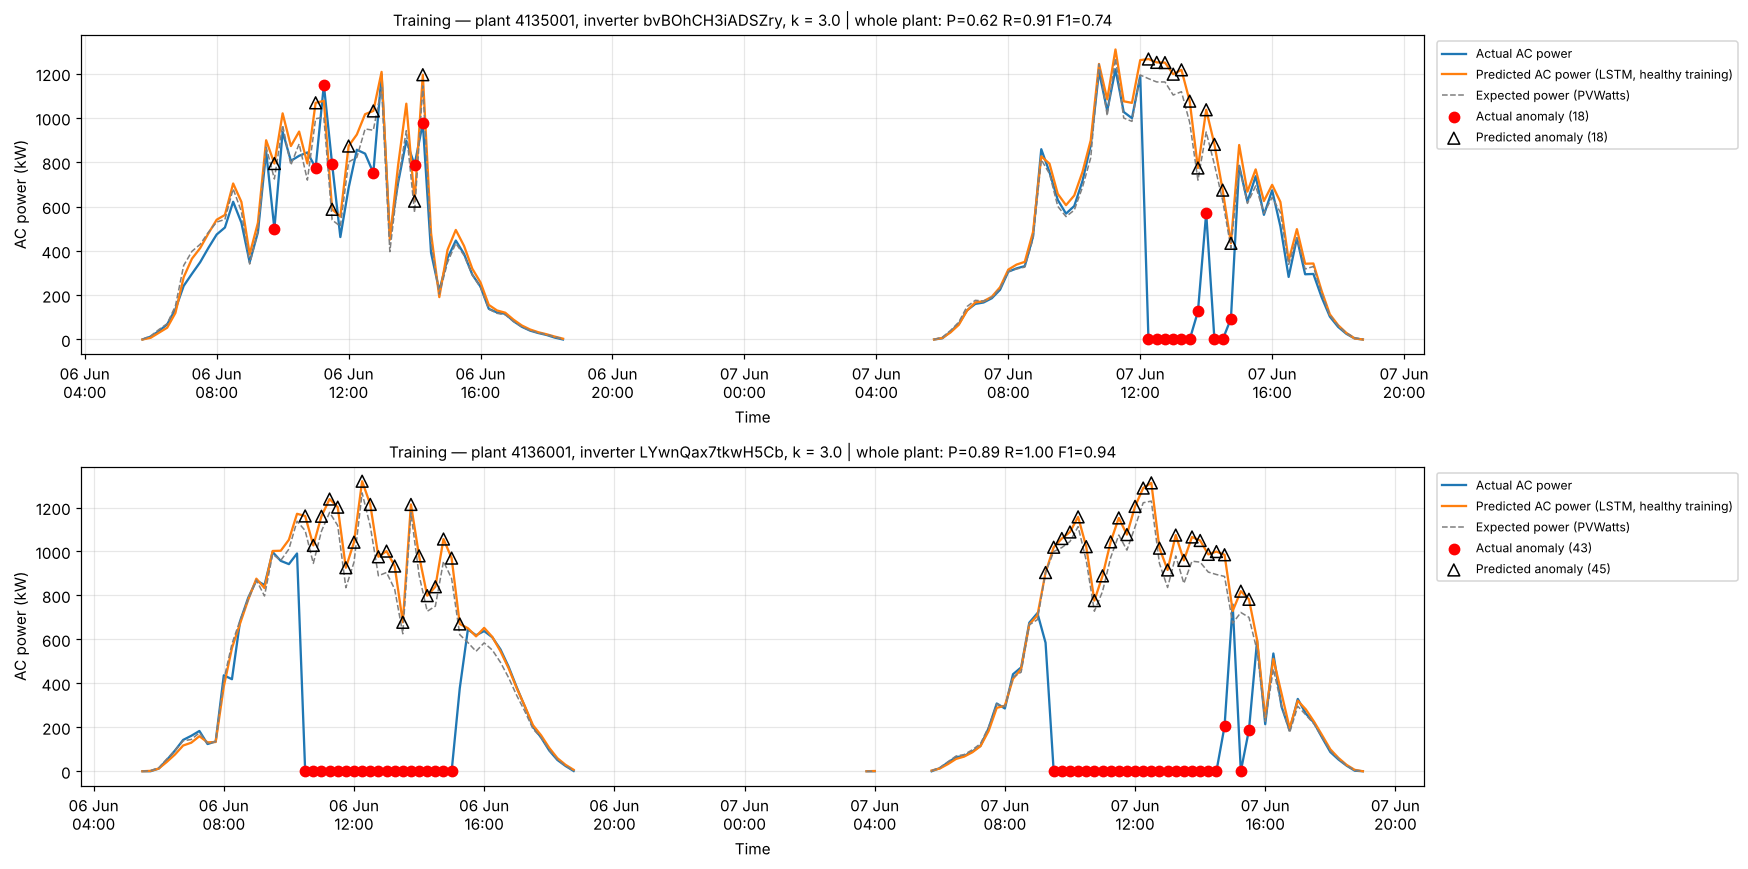

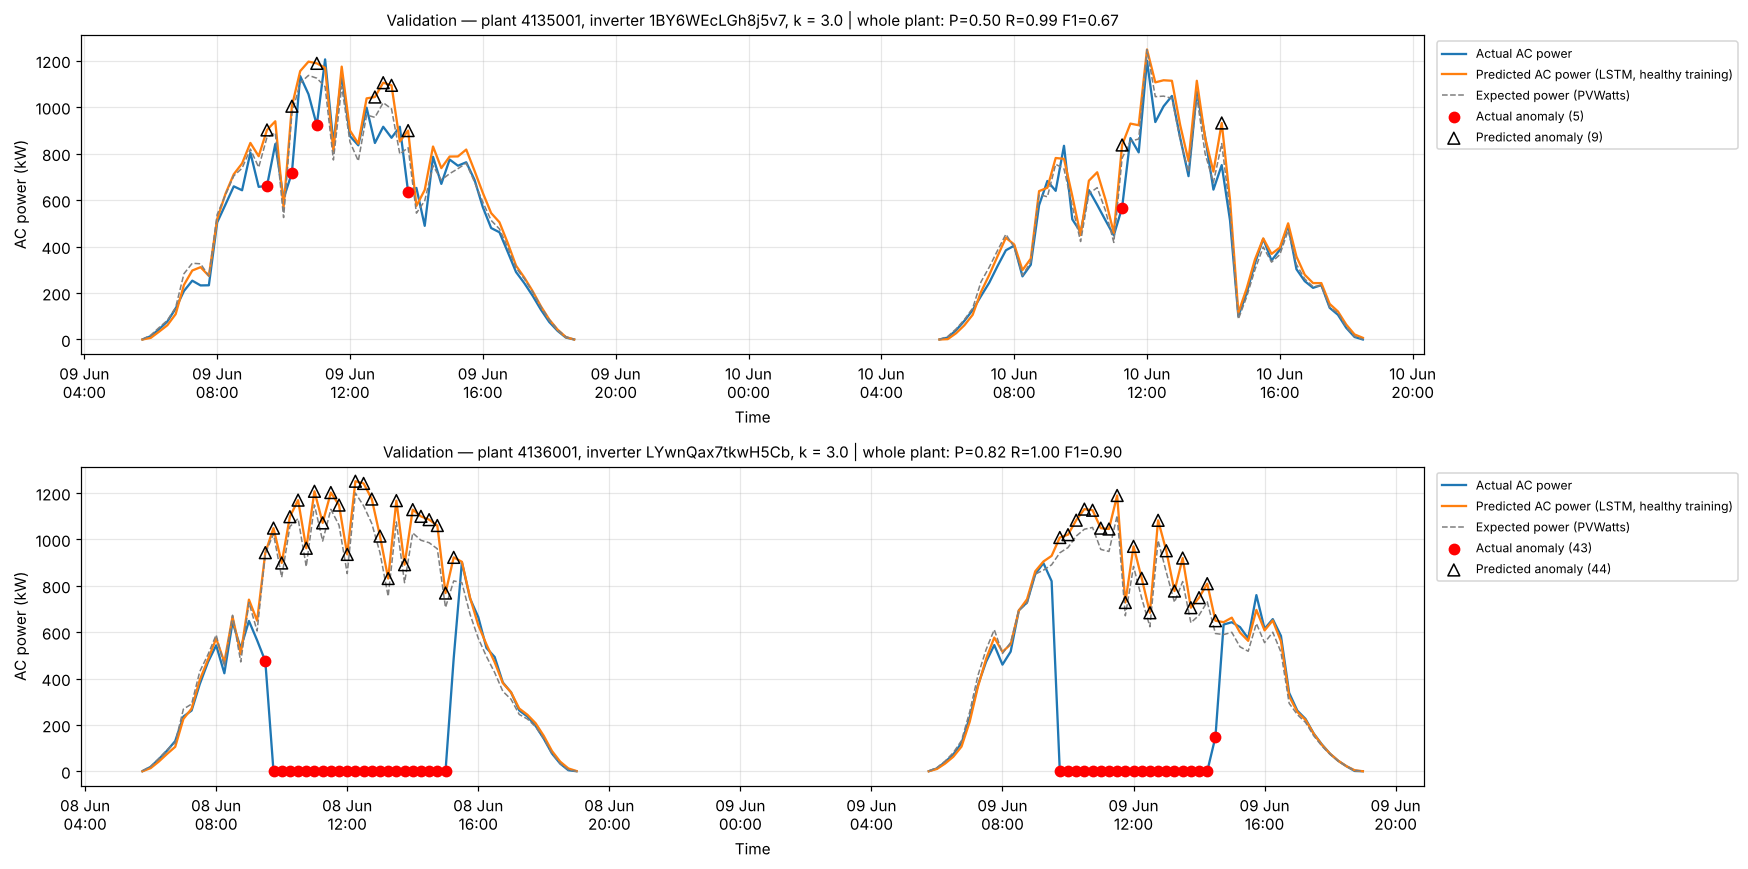

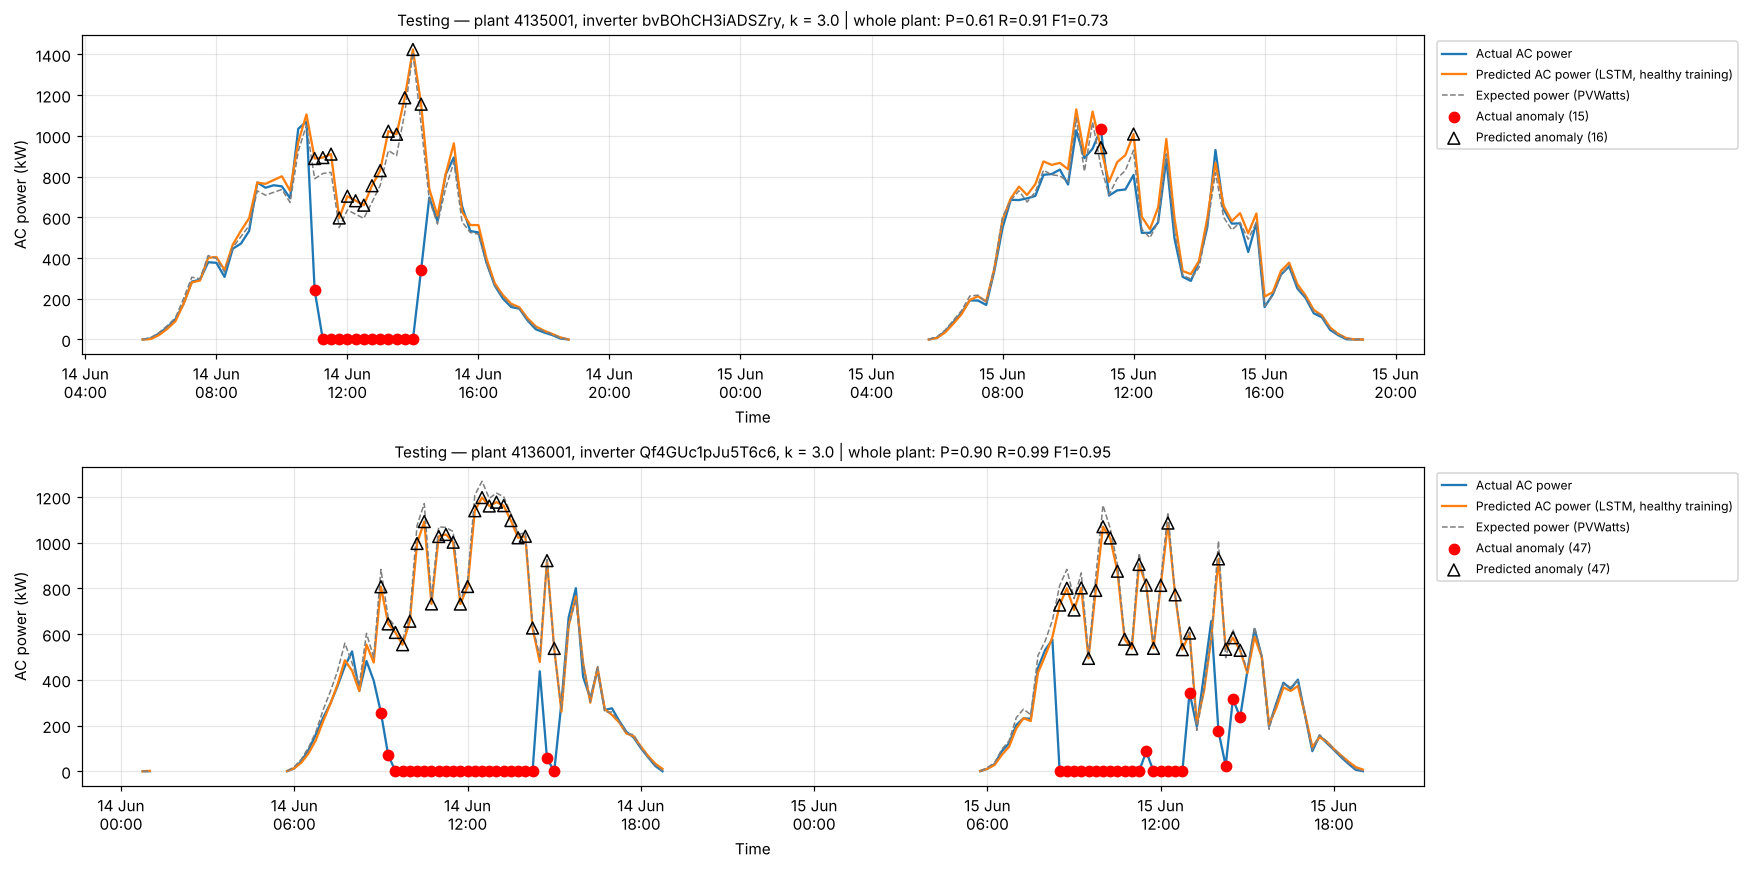

In [5]:
# Cell 5 — Plot 1: actual vs predicted for each stage, one example inverter from EACH plant
def draw_panel(ax, w, title, show_old=False):
    ax.plot(w.index, w['ACTUAL_AC_POWER_kW'], color=C_ACT, label='Actual AC power')
    ax.plot(w.index, w['PREDICTED_AC_POWER_kW'], color=C_PRED, label='Predicted AC power (LSTM, healthy training)')
    if show_old:
        ax.plot(w.index, w['PREDICTED_ALL_DATA_kW'], color=C_OLD, linewidth=1.3, linestyle='-.',
                label='Previous LSTM (trained on all readings)')
    ax.plot(w.index, w['EXPECTED_PHYS_kW'], color=C_PHYS, linewidth=1, linestyle='--', label='Expected power (PVWatts)')
    a = w[w[f'actual_anomaly_k{K}'] == 1]
    pr = w[w[f'pred_anomaly_k{K}'] == 1]
    ax.scatter(a.index, a['ACTUAL_AC_POWER_kW'], color='red', s=45, zorder=4, label=f'Actual anomaly ({len(a)})')
    ax.scatter(pr.index, pr['PREDICTED_AC_POWER_kW'], marker='^', facecolor='none', edgecolor='black', s=60,
               zorder=5, label=f'Predicted anomaly ({len(pr)})')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Time'); ax.set_ylabel('AC power (kW)'); time_axis(ax)
    ax.legend(loc='upper left', bbox_to_anchor=(1.005, 1.0), fontsize=8)

for s in SPLITS:
    fig, axes = plt.subplots(len(PLANTS), 1, figsize=(16, 4 * len(PLANTS)))
    for ax, p in zip(axes, PLANTS):
        inv, start, end = EXAMPLE_PLANT[s][p]
        P, R, F = scores(result_column(data[s][data[s]['PLANT_ID'] == p], K, MAIN))
        draw_panel(ax, window(data[s], inv, start, end),
                   f'{NAMES[s]} — plant {p}, inverter {inv}, k = {K} | whole plant: P={P:.2f} R={R:.2f} F1={F:.2f}')
    fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, f'1_actual_vs_predicted_{s}.png'), dpi=150); plt.show()

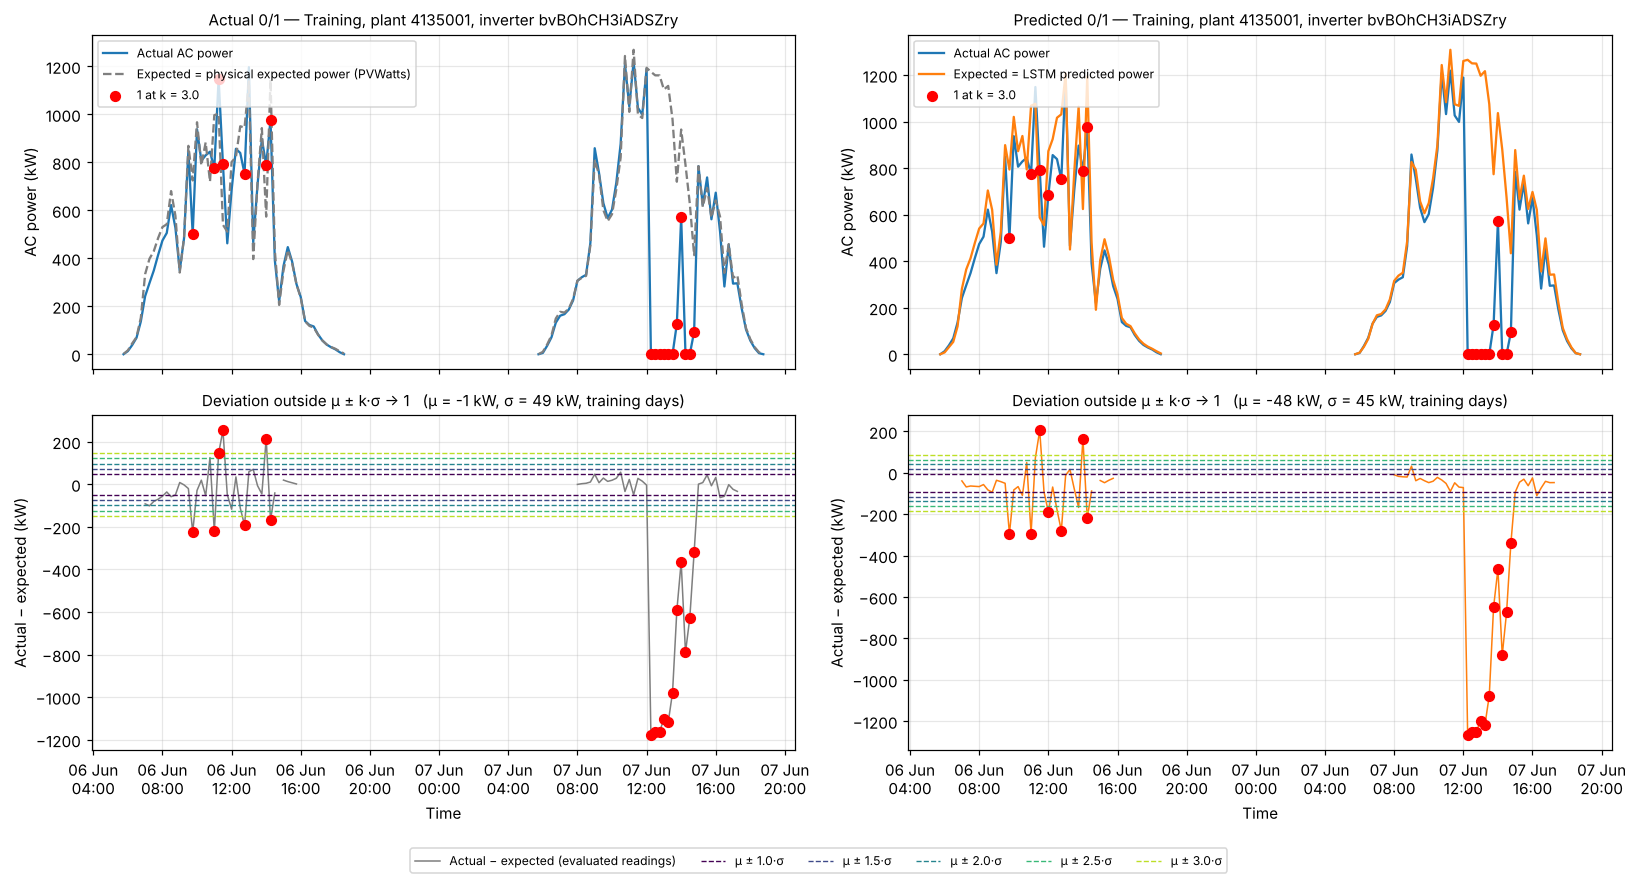

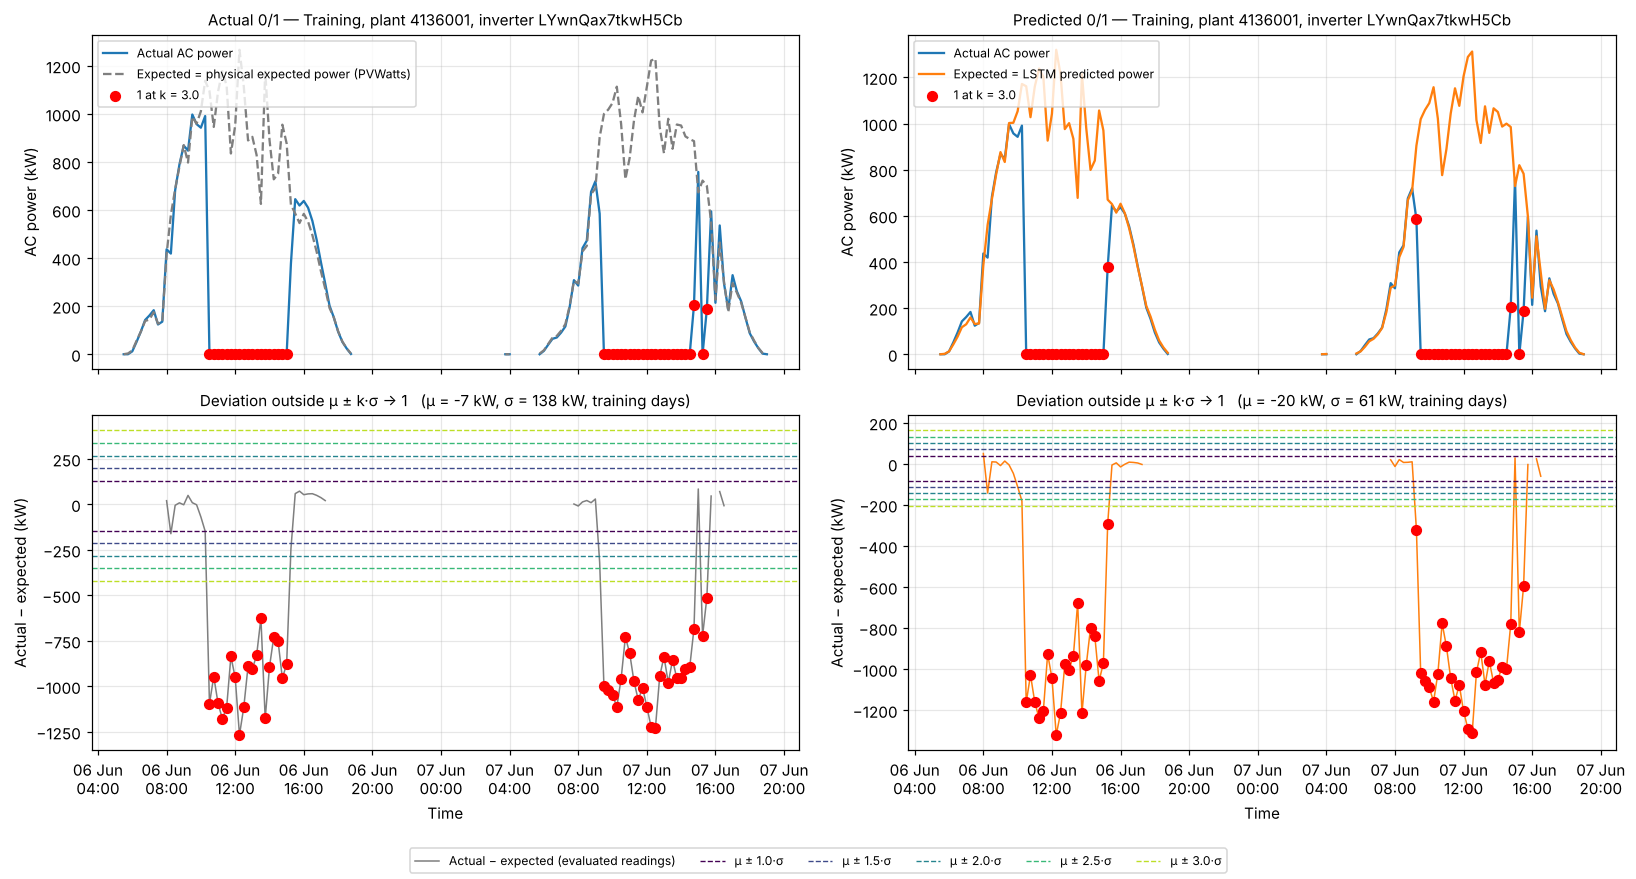

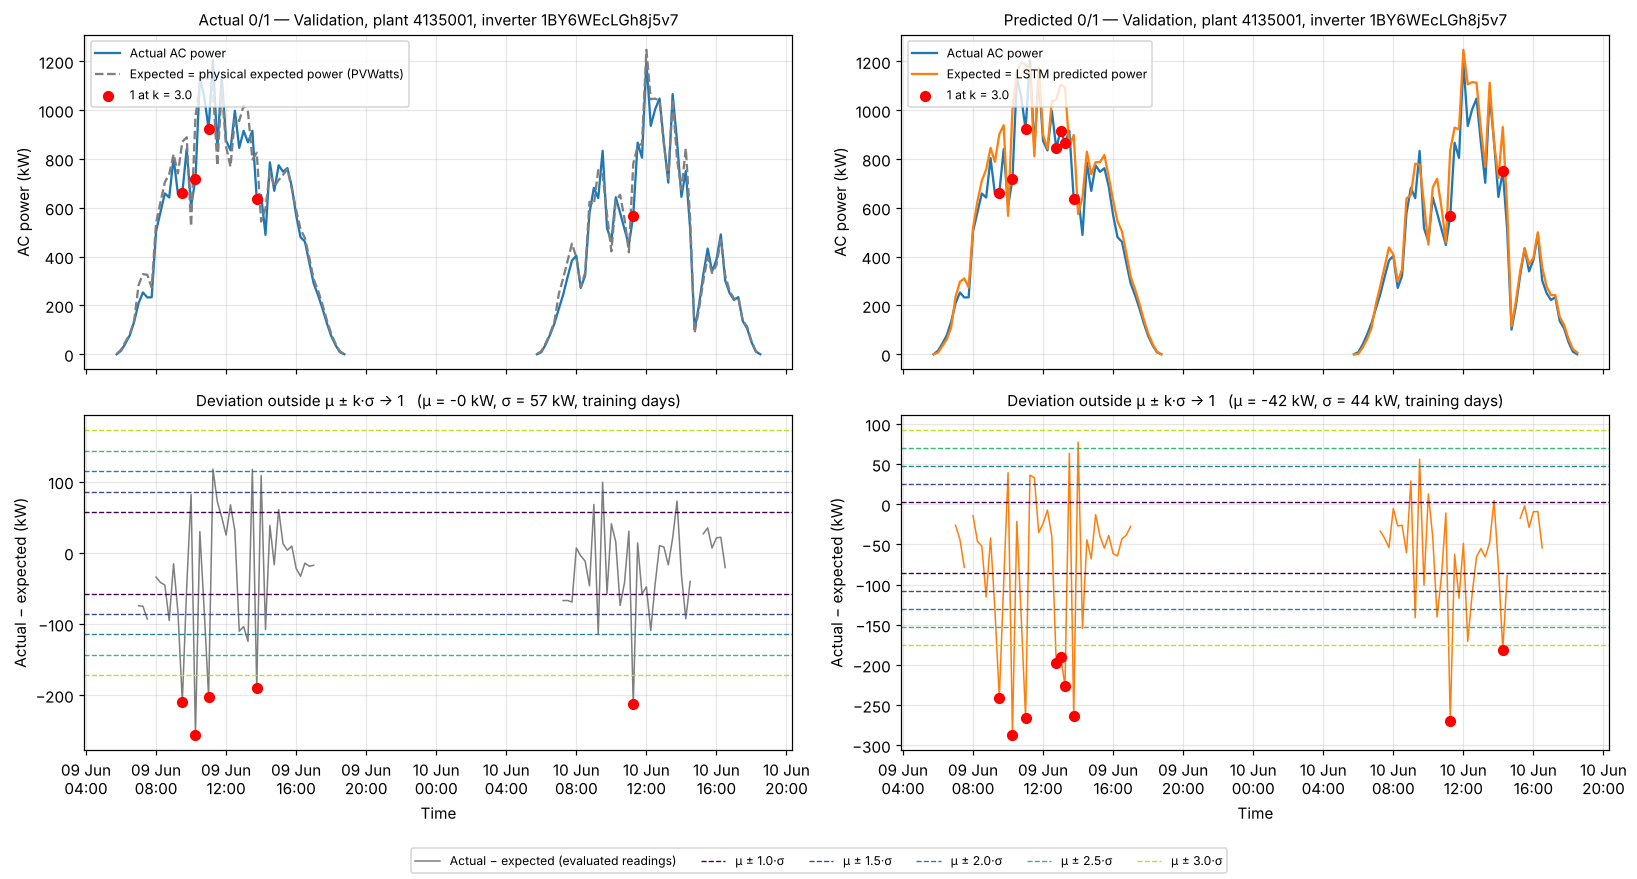

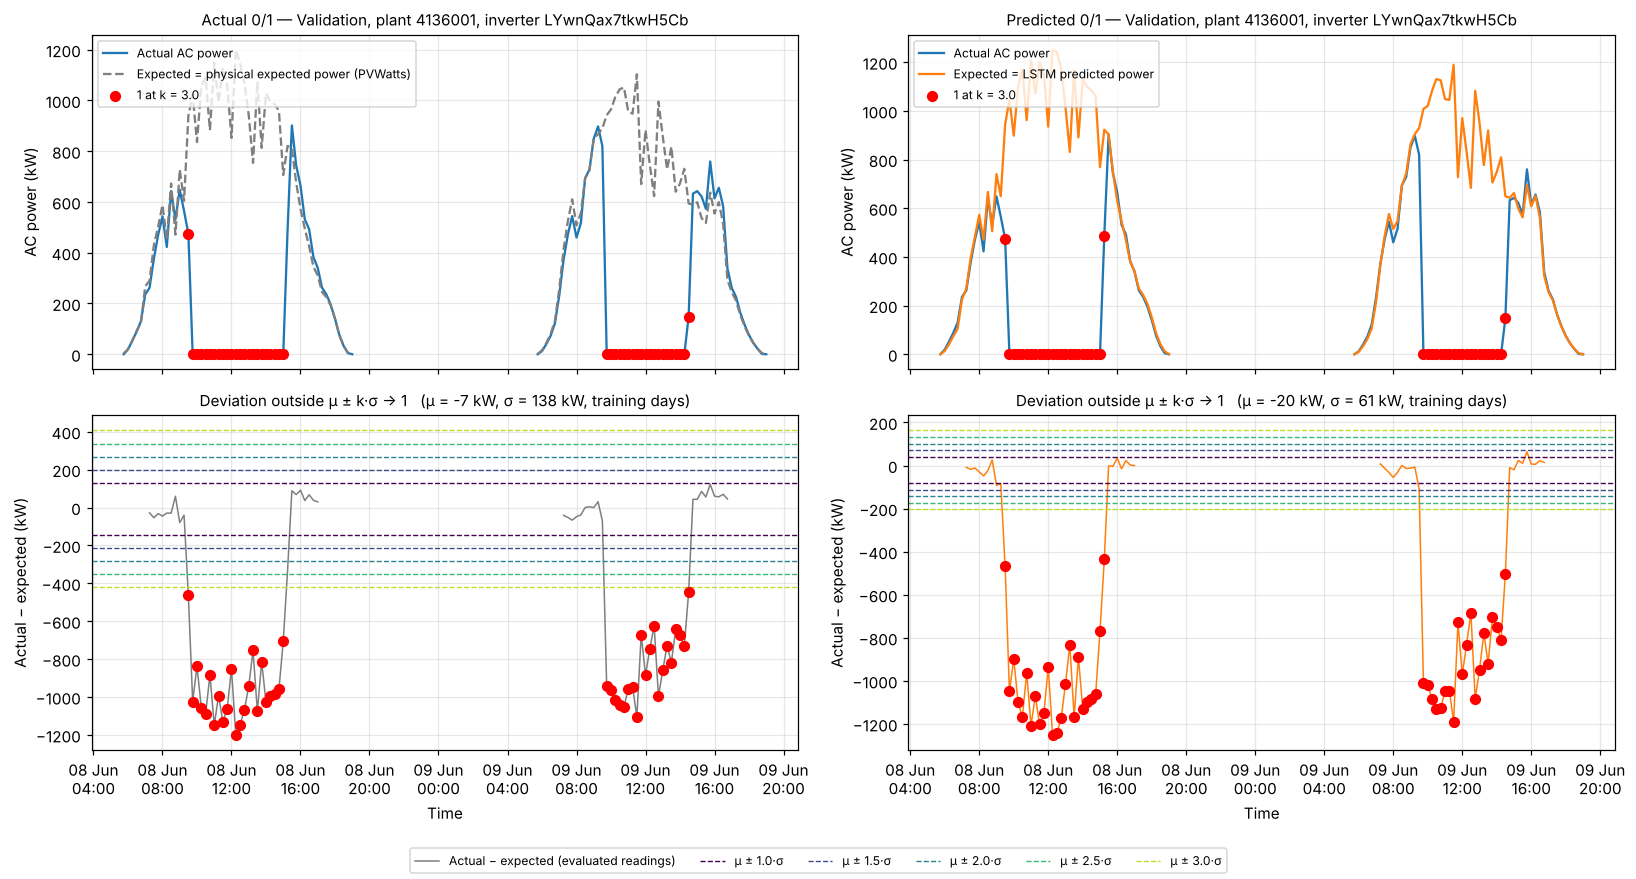

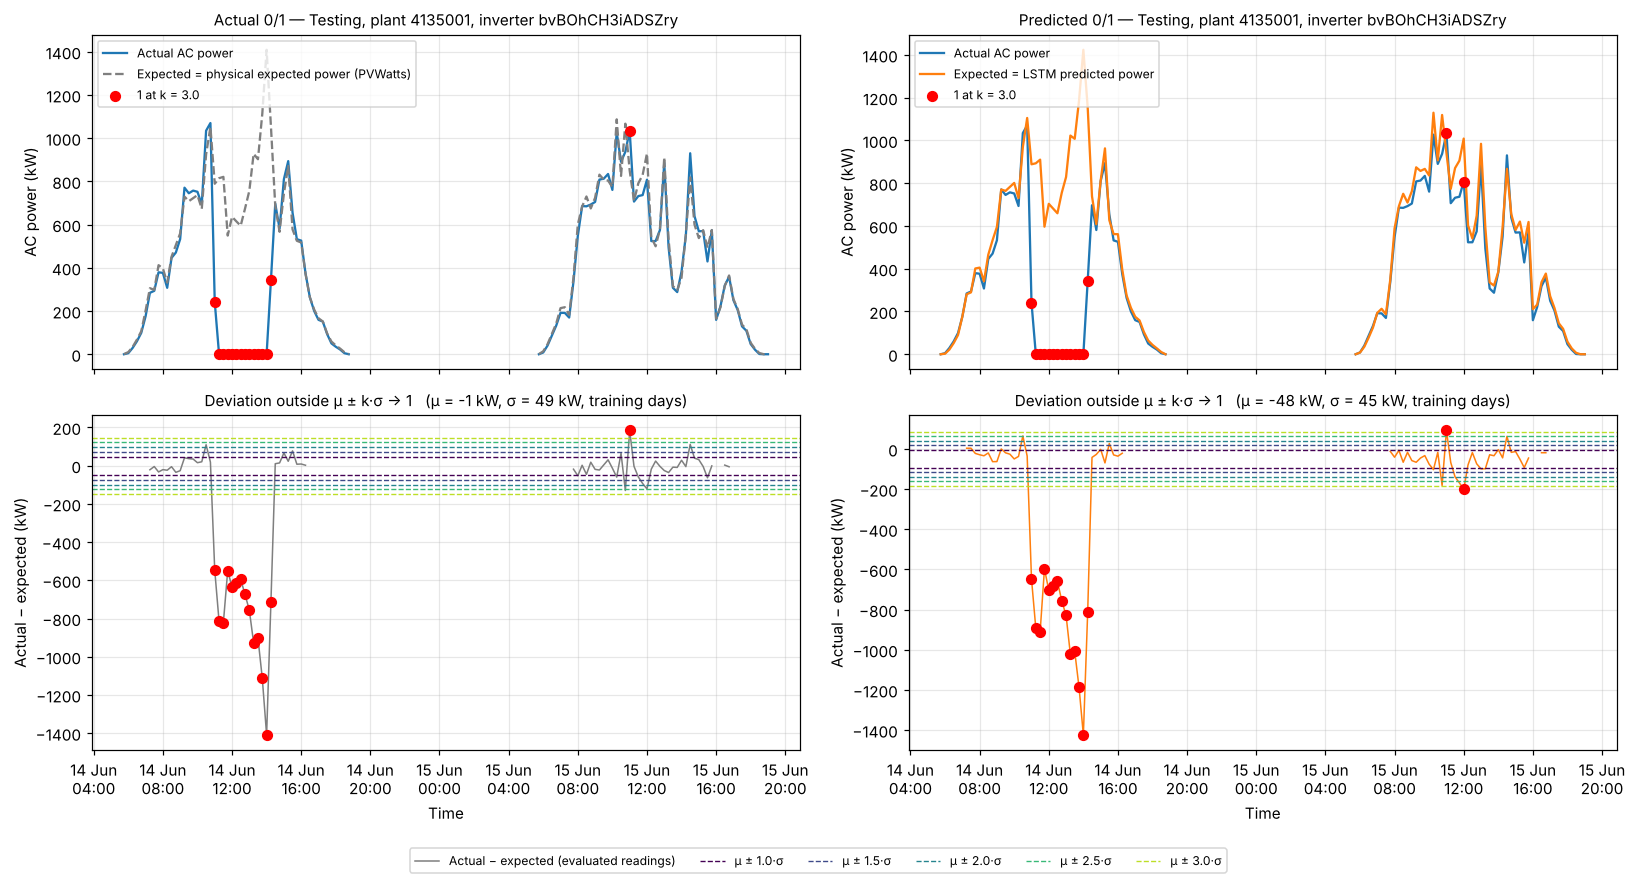

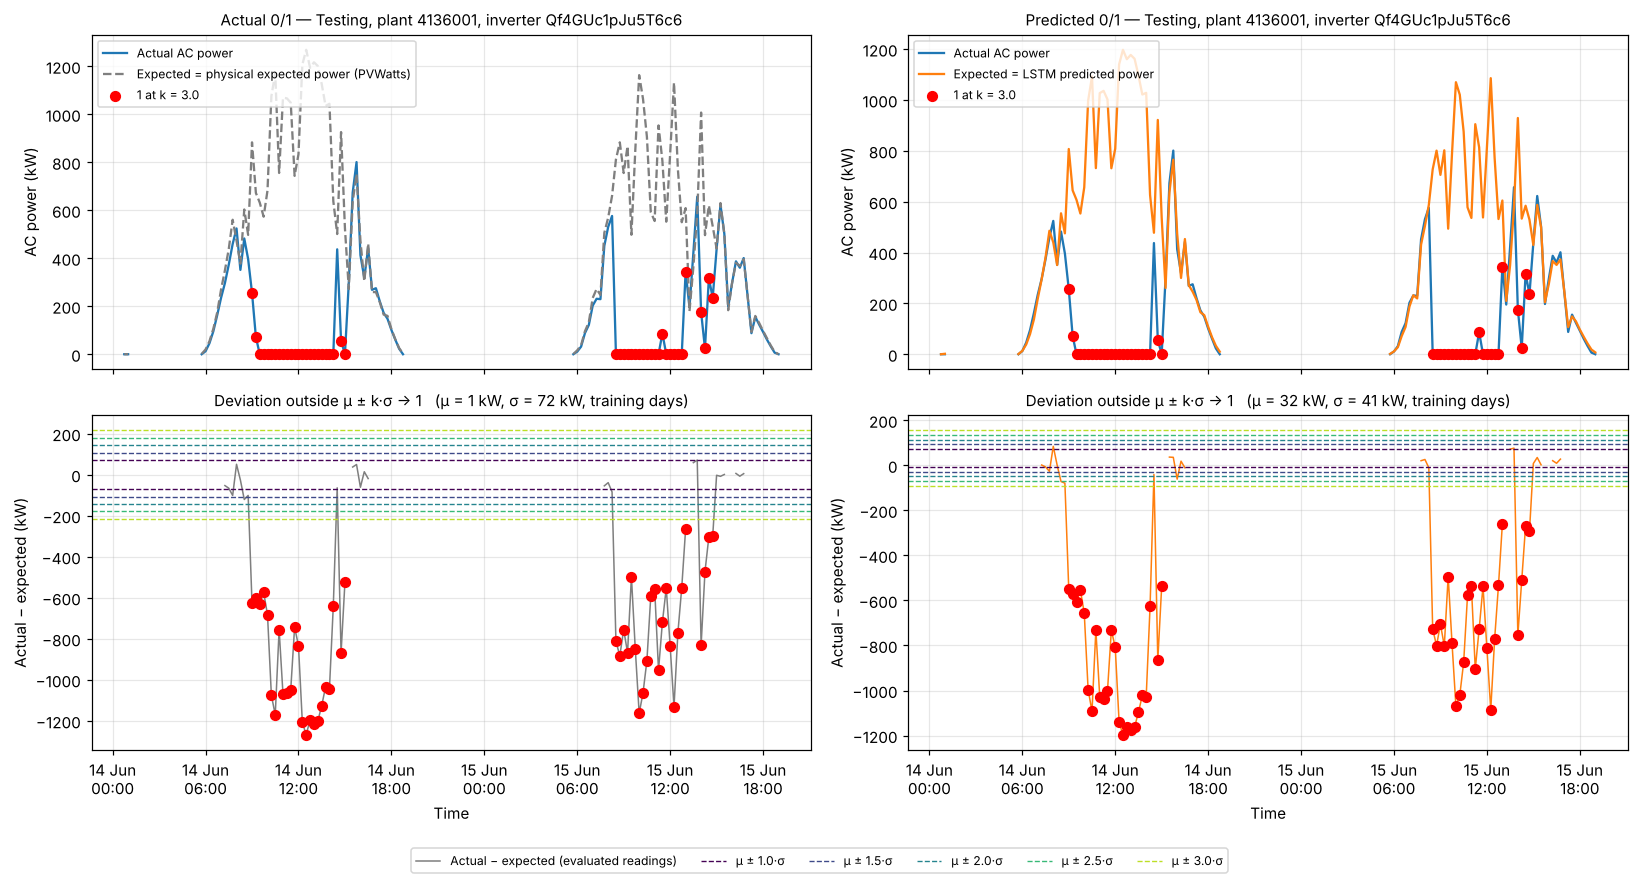

Limits drawn above reproduce the 0/1 columns of Notebook 3 for every k, stage and plant (checked).


In [6]:
# Cell 6 — Plot 2: how each line becomes 0/1 (the rule of Notebook 3, drawn for every k)
#   value used = actual − expected power;  limits = mu ± k·sigma of this inverter (training days only)
K_COLORS = plt.cm.viridis(np.linspace(0, 0.9, len(K_VALUES)))
for s in SPLITS:
    for p in PLANTS:
        inv, start, end = EXAMPLE_PLANT[s][p]
        w = window(data[s], inv, start, end)
        fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
        for col_i, (line, exp_col, exp_name, color) in enumerate([
                ('actual', 'EXPECTED_PHYS_kW', 'physical expected power (PVWatts)', C_PHYS),
                ('pred', 'PREDICTED_AC_POWER_kW', 'LSTM predicted power', C_PRED)]):
            mu, sd = limits.loc[inv, f'{line}_mu'], limits.loc[inv, f'{line}_sigma']
            d = data[s][data[s]['SOURCE_KEY'] == inv]
            for k in K_VALUES:      # check: the limits drawn here give exactly the 0/1 of Notebook 3
                r = d['ACTUAL_AC_POWER_kW'] - d[exp_col]
                mine = (((r > mu + k * sd) | (r < mu - k * sd)) & (d['EVALUATED'] == 1)).astype(int)
                assert (mine.values == d[f'{line}_anomaly_k{k}'].values).all(), (s, p, line, k)
            top, bottom = axes[0, col_i], axes[1, col_i]
            top.plot(w.index, w['ACTUAL_AC_POWER_kW'], color=C_ACT, label='Actual AC power')
            top.plot(w.index, w[exp_col], color=color, linewidth=1.5, linestyle='--' if line == 'actual' else '-',
                     label=f'Expected = {exp_name}')
            hit = w[w[f'{line}_anomaly_k{K}'] == 1]
            top.scatter(hit.index, hit['ACTUAL_AC_POWER_kW'], color='red', s=40, zorder=4, label=f'1 at k = {K}')
            top.set_title(f'{"Actual 0/1" if line == "actual" else "Predicted 0/1"} — {NAMES[s]}, plant {p}, inverter {inv}', fontsize=10)
            top.set_ylabel('AC power (kW)'); top.legend(fontsize=8, loc='upper left')
            resid = w[f'RESID_{line.upper()}_kW'].where(w['EVALUATED'] == 1)
            bottom.plot(w.index, resid, color=color, linewidth=1, label='Actual − expected (evaluated readings)')
            for k, kc in zip(K_VALUES, K_COLORS):
                bottom.axhline(mu + k * sd, color=kc, linewidth=0.9, linestyle='--', label=f'μ ± {k}·σ')
                bottom.axhline(mu - k * sd, color=kc, linewidth=0.9, linestyle='--')
            bottom.scatter(hit.index, hit[f'RESID_{line.upper()}_kW'], color='red', s=40, zorder=4)
            bottom.set_title(f'Deviation outside μ ± k·σ → 1   (μ = {mu:.0f} kW, σ = {sd:.0f} kW, training days)', fontsize=10)
            bottom.set_xlabel('Time'); bottom.set_ylabel('Actual − expected (kW)'); time_axis(bottom)
        fig.legend(*axes[1, 0].get_legend_handles_labels(), loc='lower center', ncol=6, fontsize=8)
        fig.tight_layout(rect=[0, 0.04, 1, 1])
        fig.savefig(os.path.join(PLOT_DIR, f'2_anomaly_calculation_{s}_plant_{p}.png'), dpi=150); plt.show()
print('Limits drawn above reproduce the 0/1 columns of Notebook 3 for every k, stage and plant (checked).')

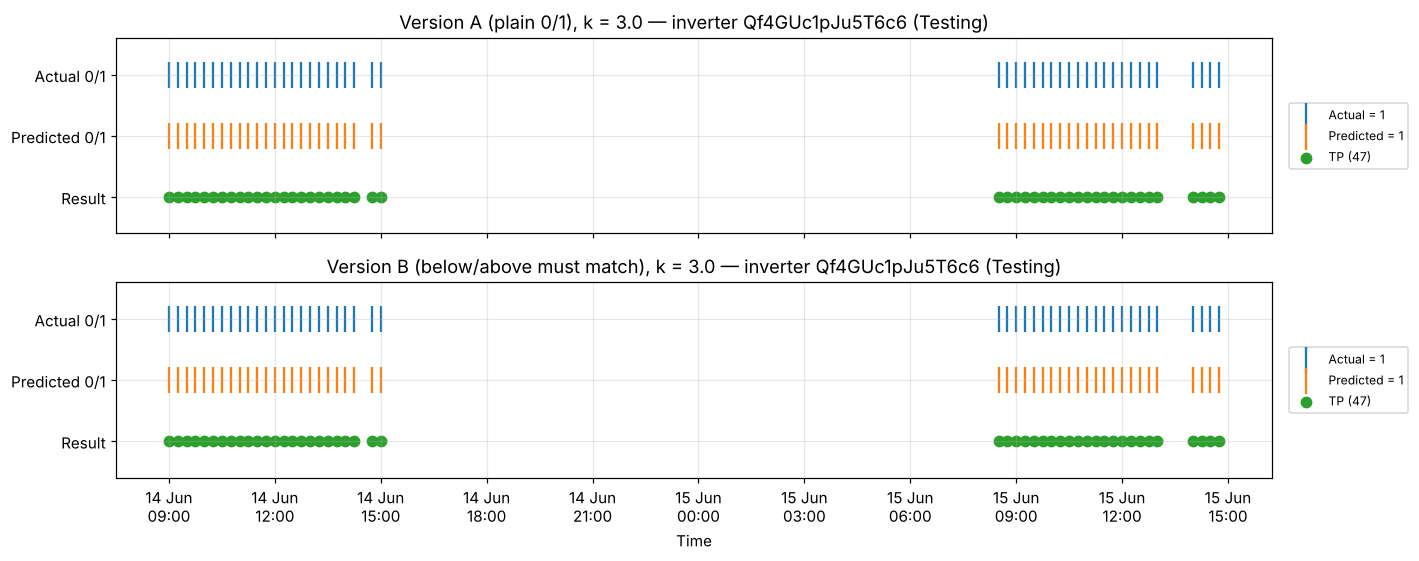

In [7]:
# Cell 7 — Plot 3: comparing the two 0/1 columns (how TP / FP / FN are counted)
s = 'test'
inv, start, end = EXAMPLE[s]
fig, axes = plt.subplots(2, 1, figsize=(13, 5.2), sharex=True)
for ax, v in zip(axes, ['A', 'B']):
    k = BEST_K[v]
    d = data[s].copy()
    d['result'] = result_column(d, k, v)
    w = window(d, inv, start, end)
    act = w[f'actual_anomaly_k{k}'] == 1
    pre = w[f'pred_anomaly_k{k}'] == 1
    ax.scatter(w.index[act], np.full(act.sum(), 2), marker='|', s=300, color=C_ACT, label='Actual = 1')
    ax.scatter(w.index[pre], np.full(pre.sum(), 1), marker='|', s=300, color=C_PRED, label='Predicted = 1')
    for r, c in C_RES.items():
        m = w['result'] == r
        if m.any():
            ax.scatter(w.index[m], np.zeros(m.sum()), color=c, s=45, label=f'{r} ({m.sum()})')
    ax.set_yticks([0, 1, 2]); ax.set_yticklabels(['Result', 'Predicted 0/1', 'Actual 0/1'])
    ax.set_ylim(-0.6, 2.6)
    ax.set_title(f'{VERSION_TXT[v]}, k = {k} — inverter {inv} ({NAMES[s]})')
    ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=8)
axes[-1].set_xlabel('Time'); time_axis(axes[-1])
fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, '3_actual_vs_predicted_vectors.png'), dpi=150, bbox_inches='tight'); plt.show()

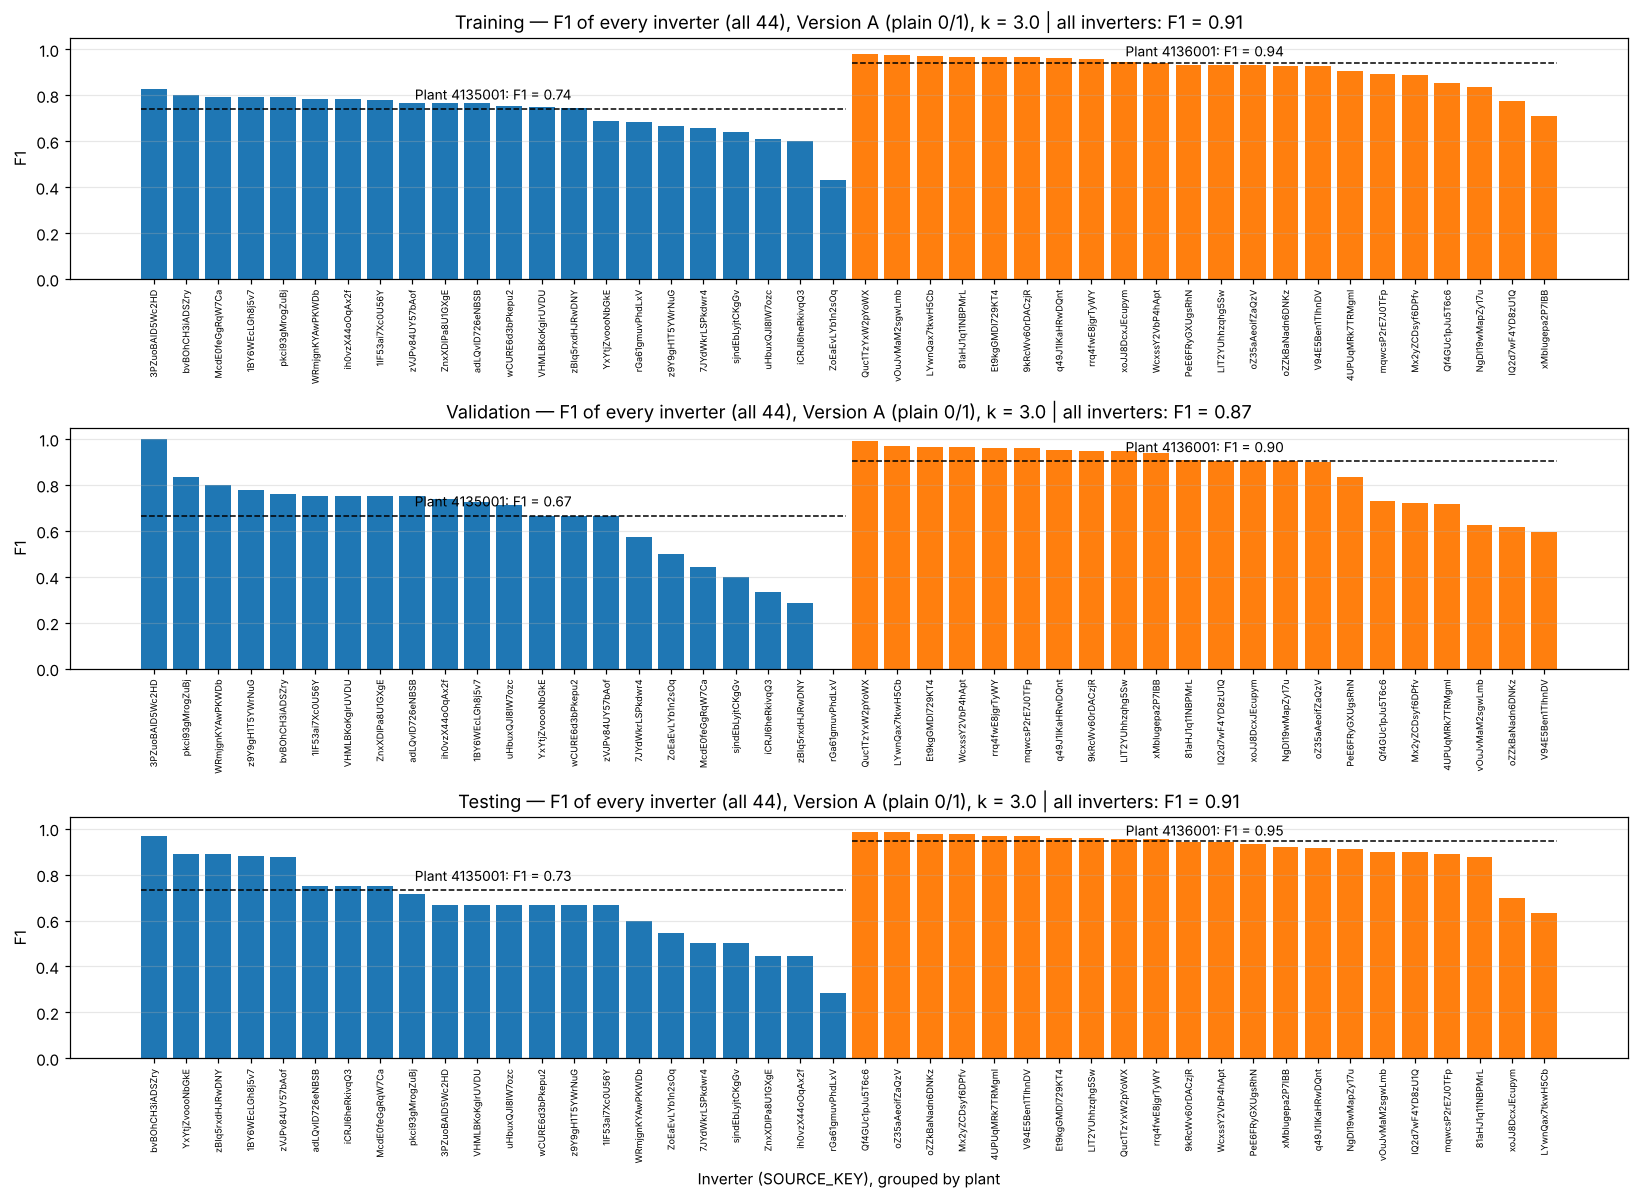

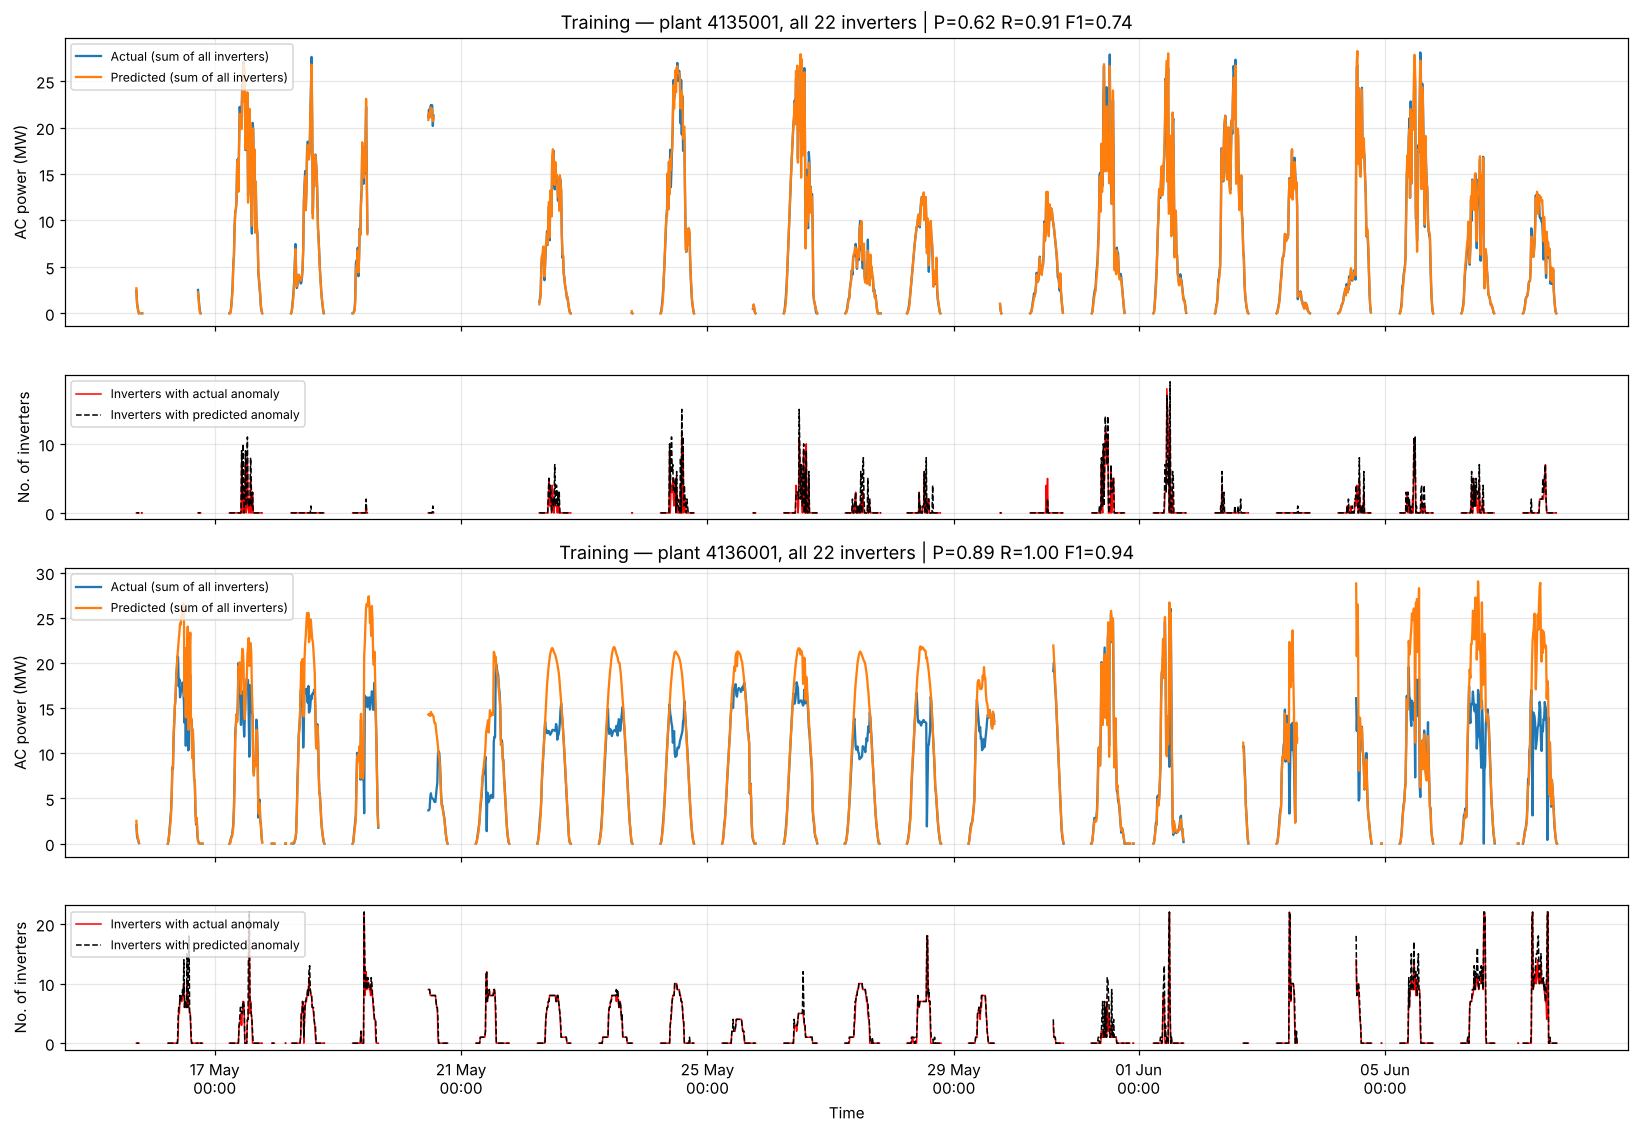

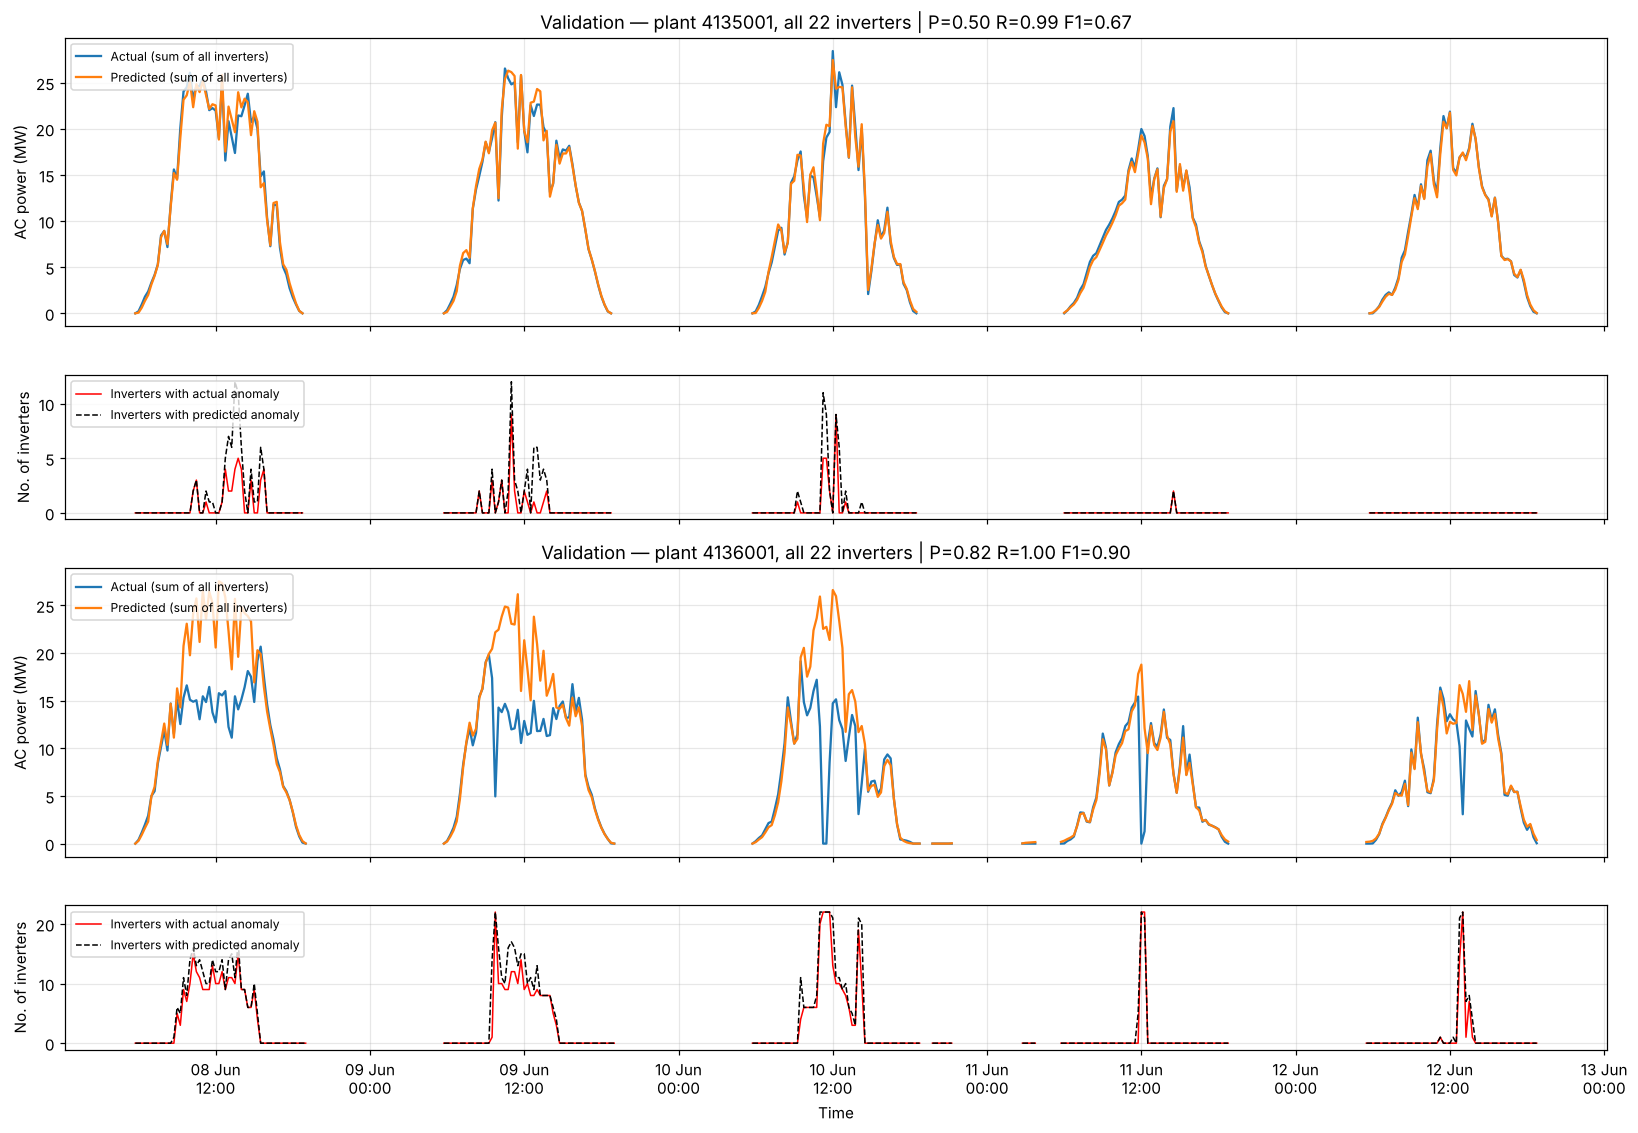

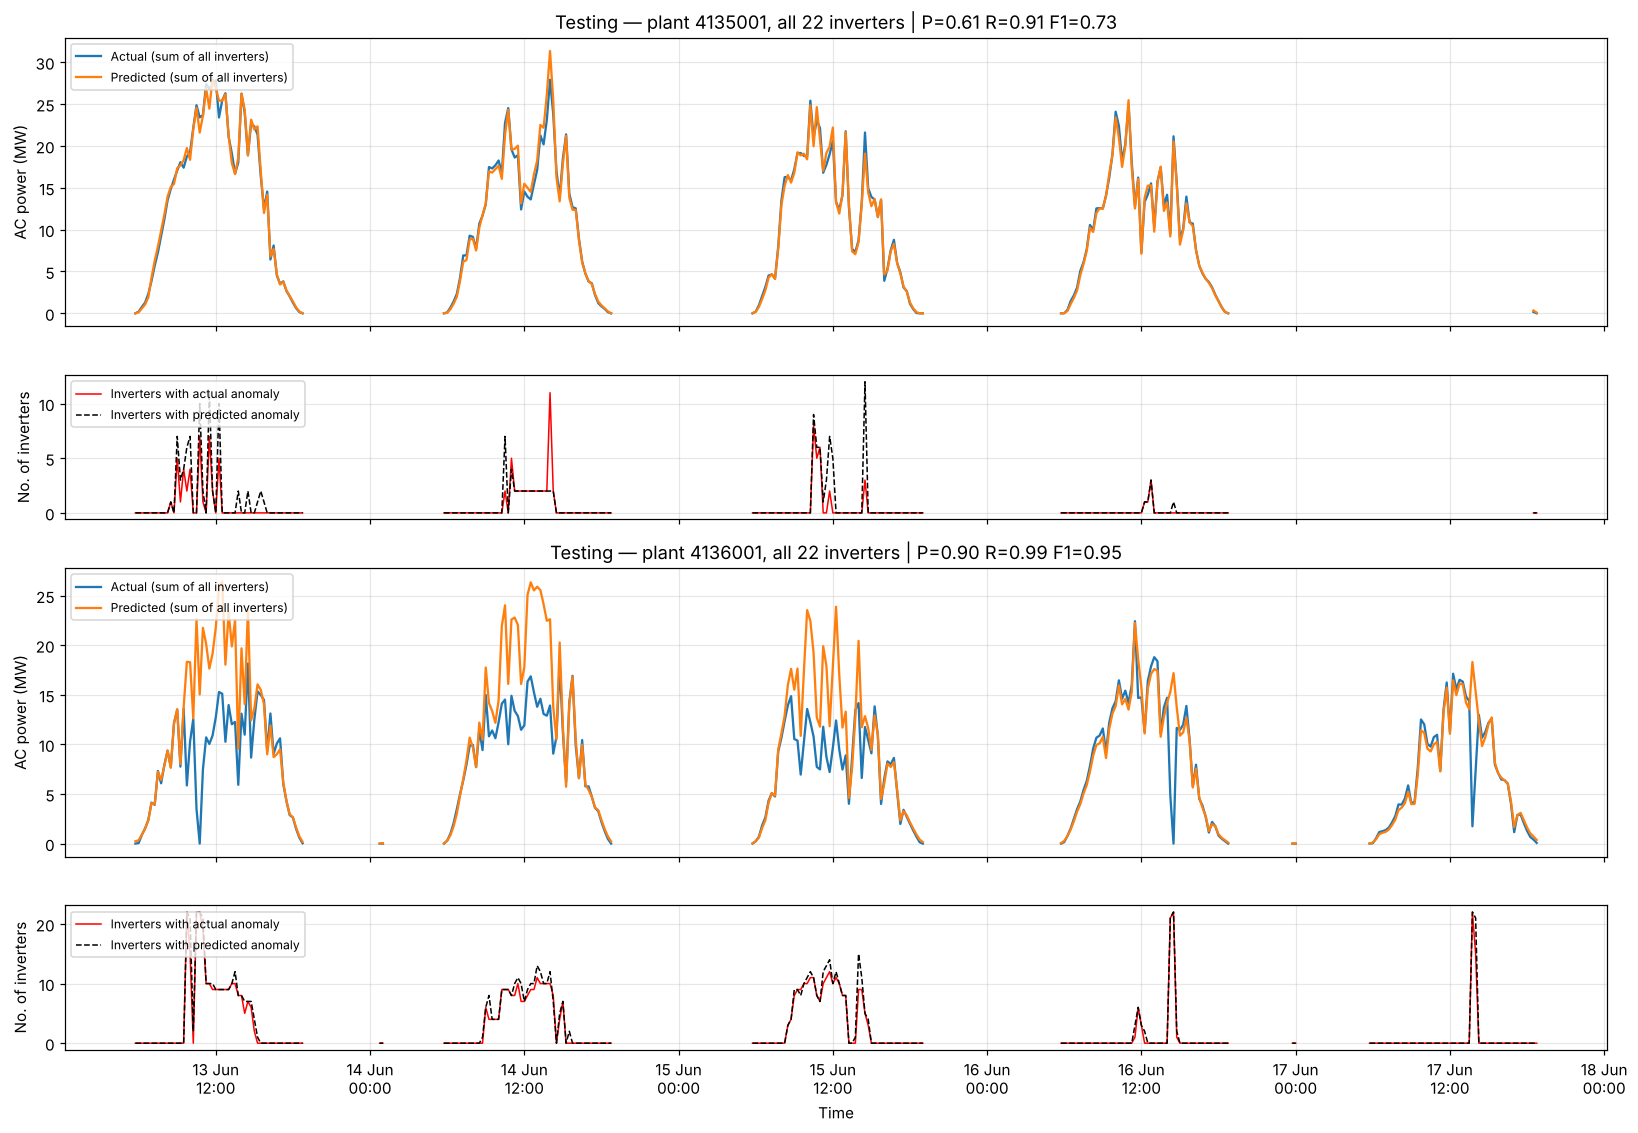

count  mean   min   max
Split      PLANT_ID                         
Testing    4135001    22.0  0.67  0.29  0.97
           4136001    22.0  0.92  0.63  0.99
Training   4135001    22.0  0.72  0.43  0.83
           4136001    22.0  0.92  0.71  0.98
Validation 4135001    22.0  0.63  0.00  1.00
           4136001    22.0  0.86  0.60  0.99

In [8]:
# Cell 7b — Plot 7: COMPLETE results for ALL inverters (not one example)
rows = []
for s in SPLITS:
    for (p, inv), g in data[s].groupby(['PLANT_ID', 'SOURCE_KEY']):
        P, R, F = scores(result_column(g, K, MAIN))
        rows.append({'Split': NAMES[s], 'PLANT_ID': p, 'SOURCE_KEY': inv, 'Precision': P, 'Recall': R, 'F1': F})
per_inv = pd.DataFrame(rows)
per_inv.round(4).to_csv(os.path.join(OUT_DIR, 'metrics_per_inverter.csv'), index=False)

fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharey=True)
for ax, s in zip(axes, SPLITS):
    m = per_inv[per_inv['Split'] == NAMES[s]].sort_values(['PLANT_ID', 'F1'], ascending=[True, False]).reset_index(drop=True)
    colors = [C_ACT if p == PLANTS[0] else C_PRED for p in m['PLANT_ID']]
    ax.bar(range(len(m)), m['F1'], color=colors)
    for p, c in zip(PLANTS, [C_ACT, C_PRED]):
        idx = m.index[m['PLANT_ID'] == p]
        P, R, F = scores(result_column(data[s][data[s]['PLANT_ID'] == p], K, MAIN))
        ax.hlines(F, idx.min() - 0.4, idx.max() + 0.4, color='black', linestyle='--', linewidth=1)
        ax.text((idx.min() + idx.max()) / 2, min(F + 0.04, 0.97), f'Plant {p}: F1 = {F:.2f}', ha='center', fontsize=9)
    ax.set_xticks(range(len(m))); ax.set_xticklabels(m['SOURCE_KEY'], rotation=90, fontsize=6)
    ax.set_ylim(0, 1.05); ax.set_ylabel('F1'); ax.grid(axis='x', visible=False)
    P, R, F = scores(result_column(data[s], K, MAIN))
    ax.set_title(f'{NAMES[s]} — F1 of every inverter (all 44), {VERSION_TXT[MAIN]}, k = {K} | all inverters: F1 = {F:.2f}')
axes[-1].set_xlabel('Inverter (SOURCE_KEY), grouped by plant')
fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, '7a_f1_every_inverter.png'), dpi=150); plt.show()

for s in SPLITS:
    fig, axes = plt.subplots(2 * len(PLANTS), 1, figsize=(15, 4.2 * len(PLANTS) + 2), sharex=True,
                             gridspec_kw={'height_ratios': [2, 1] * len(PLANTS)})
    for i, p in enumerate(PLANTS):
        d = data[s][data[s]['PLANT_ID'] == p]
        t = d.groupby('DATE_TIME').agg(actual=('ACTUAL_AC_POWER_kW', 'sum'), predicted=('PREDICTED_AC_POWER_kW', 'sum'),
                                       n_act=(f'actual_anomaly_k{K}', 'sum'), n_pred=(f'pred_anomaly_k{K}', 'sum'))
        grid = pd.date_range(t.index.min().normalize(), t.index.max().normalize() + pd.Timedelta('1D') - pd.Timedelta('15min'), freq='15min')
        t = t.reindex(grid)
        top, bottom = axes[2 * i], axes[2 * i + 1]
        top.plot(t.index, t['actual'] / 1000, color=C_ACT, label='Actual (sum of all inverters)')
        top.plot(t.index, t['predicted'] / 1000, color=C_PRED, label='Predicted (sum of all inverters)')
        P, R, F = scores(result_column(d, K, MAIN))
        top.set_title(f'{NAMES[s]} — plant {p}, all {d["SOURCE_KEY"].nunique()} inverters | P={P:.2f} R={R:.2f} F1={F:.2f}')
        top.set_ylabel('AC power (MW)'); top.legend(loc='upper left', fontsize=8)
        bottom.plot(t.index, t['n_act'], color='red', linewidth=1, label='Inverters with actual anomaly')
        bottom.plot(t.index, t['n_pred'], color='black', linewidth=1, linestyle='--', label='Inverters with predicted anomaly')
        bottom.set_ylabel('No. of inverters'); bottom.legend(loc='upper left', fontsize=8)
    axes[-1].set_xlabel('Time'); time_axis(axes[-1])
    fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, f'7b_all_inverters_{s}.png'), dpi=150); plt.show()

per_inv.groupby(['Split', 'PLANT_ID'])['F1'].describe()[['count', 'mean', 'min', 'max']].round(2)

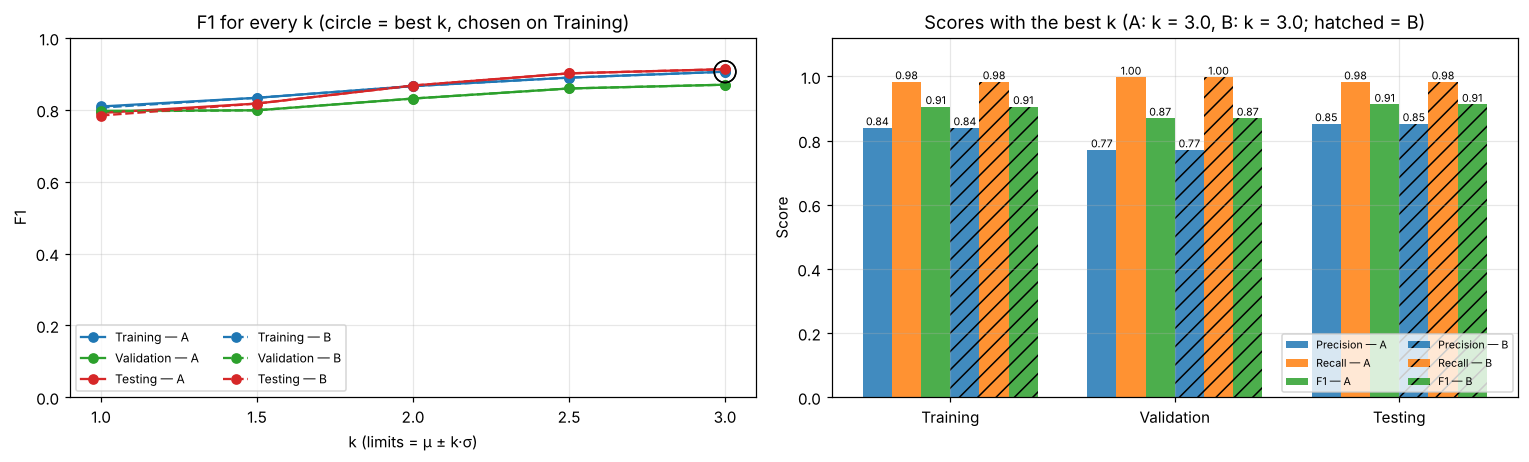

,Version,Split,k,TP,FP,FN,TN,Wrong_direction,Precision,Recall,F1
0,A,Training,3.0,3423,653,58,20036,NaN,0.8398,0.9833,0.9059
1,A,Validation,3.0,825,245,2,6386,NaN,0.7710,0.9976,0.8698
2,A,Testing,3.0,798,138,14,5980,NaN,0.8526,0.9828,0.9130
3,B,Training,3.0,3423,653,58,20036,0.0,0.8398,0.9833,0.9059
4,B,Validation,3.0,825,245,2,6386,0.0,0.7710,0.9976,0.8698
5,B,Testing,3.0,798,138,14,5980,0.0,0.8526,0.9828,0.9130


In [9]:
# Cell 8 — Plot 4: F1 for every k (choosing the best k on training) and the final scores of both versions
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
summary = []
for v, ls in [('A', '-'), ('B', '--')]:
    m = pd.read_csv(os.path.join(STEP4_DIR, VERSION_DIR[v], 'metrics_all_k.csv'))
    for s, c in zip(['Training', 'Validation', 'Testing'], ['#1f77b4', '#2ca02c', '#d62728']):
        mm = m[m['Split'] == s]
        axes[0].plot(mm['k'], mm['F1'], ls, marker='o', color=c, label=f'{s} — {v}')
    axes[0].scatter([BEST_K[v]], m[(m['Split'] == 'Training') & (m['k'] == BEST_K[v])]['F1'],
                    s=200, facecolor='none', edgecolor='black', zorder=5)
    r = pd.read_csv(os.path.join(STEP4_DIR, VERSION_DIR[v], 'results_best_k.csv'))
    r['Version'] = v
    summary.append(r)
axes[0].set_xticks(K_VALUES); axes[0].set_xlabel('k (limits = μ ± k·σ)'); axes[0].set_ylabel('F1'); axes[0].set_ylim(0, 1)
axes[0].set_title('F1 for every k (circle = best k, chosen on Training)')
axes[0].legend(fontsize=8, ncol=2)

summary = pd.concat(summary, ignore_index=True)
x = np.arange(len(SPLITS))
for i, (v, metric) in enumerate([(v, m) for v in ['A', 'B'] for m in ['Precision', 'Recall', 'F1']]):
    vals = summary[summary['Version'] == v][metric].values
    bars = axes[1].bar(x + (i - 2.5) * 0.13, vals, 0.13, label=f'{metric} — {v}',
                       hatch='' if v == 'A' else '//', color=['#1f77b4', '#ff7f0e', '#2ca02c'][i % 3], alpha=0.85)
    axes[1].bar_label(bars, fmt='%.2f', fontsize=7)
axes[1].set_xticks(x); axes[1].set_xticklabels([NAMES[s] for s in SPLITS])
axes[1].set_ylabel('Score'); axes[1].set_ylim(0, 1.12)
axes[1].set_title(f'Scores with the best k (A: k = {BEST_K["A"]}, B: k = {BEST_K["B"]}; hatched = B)')
axes[1].legend(fontsize=7, ncol=2, loc='lower right')
fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, '4_f1_vs_k_and_final_scores.png'), dpi=150); plt.show()

cols = ['Version', 'Split', 'k', 'TP', 'FP', 'FN', 'TN', 'Wrong_direction', 'Precision', 'Recall', 'F1']
summary = summary[[c for c in cols if c in summary.columns]]
summary.to_csv(os.path.join(OUT_DIR, 'final_results_summary.csv'), index=False)
summary

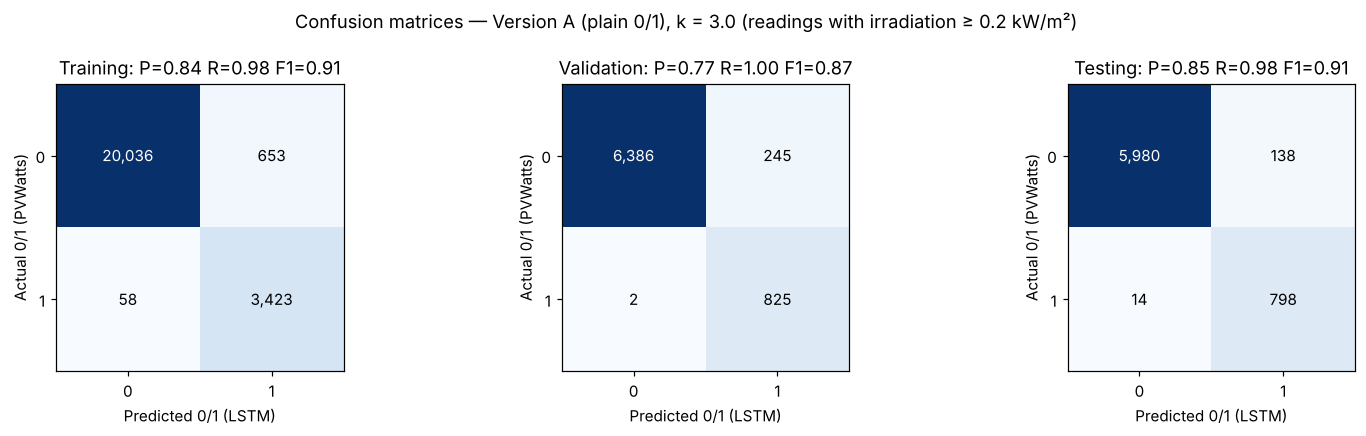

In [10]:
# Cell 9 — Plot 5: confusion matrices with the best k (main version), all three stages (evaluated readings)
labels = ['Below', 'Normal', 'Above'] if MAIN == 'B' else ['0', '1']
classes = [-1, 0, 1] if MAIN == 'B' else [0, 1]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, s in zip(axes, SPLITS):
    d = data[s][data[s]['EVALUATED'] == 1]
    a = d[f'actual_anomaly_k{K}'].values; p = d[f'pred_anomaly_k{K}'].values
    if MAIN == 'B':
        a, p = a * d['actual_dir'].values, p * d['pred_dir'].values
    cm = np.array([[((a == i) & (p == j)).sum() for j in classes] for i in classes])
    ax.imshow(cm, cmap='Blues')
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels); ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel('Predicted 0/1 (LSTM)'); ax.set_ylabel('Actual 0/1 (PVWatts)'); ax.grid(False)
    P, R, F = scores(result_column(d, K, MAIN))
    ax.set_title(f'{NAMES[s]}: P={P:.2f} R={R:.2f} F1={F:.2f}')
fig.suptitle(f'Confusion matrices — {VERSION_TXT[MAIN]}, k = {K} (readings with irradiation ≥ 0.2 kW/m²)')
fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, '5_confusion_matrices_best_k.png'), dpi=150); plt.show()

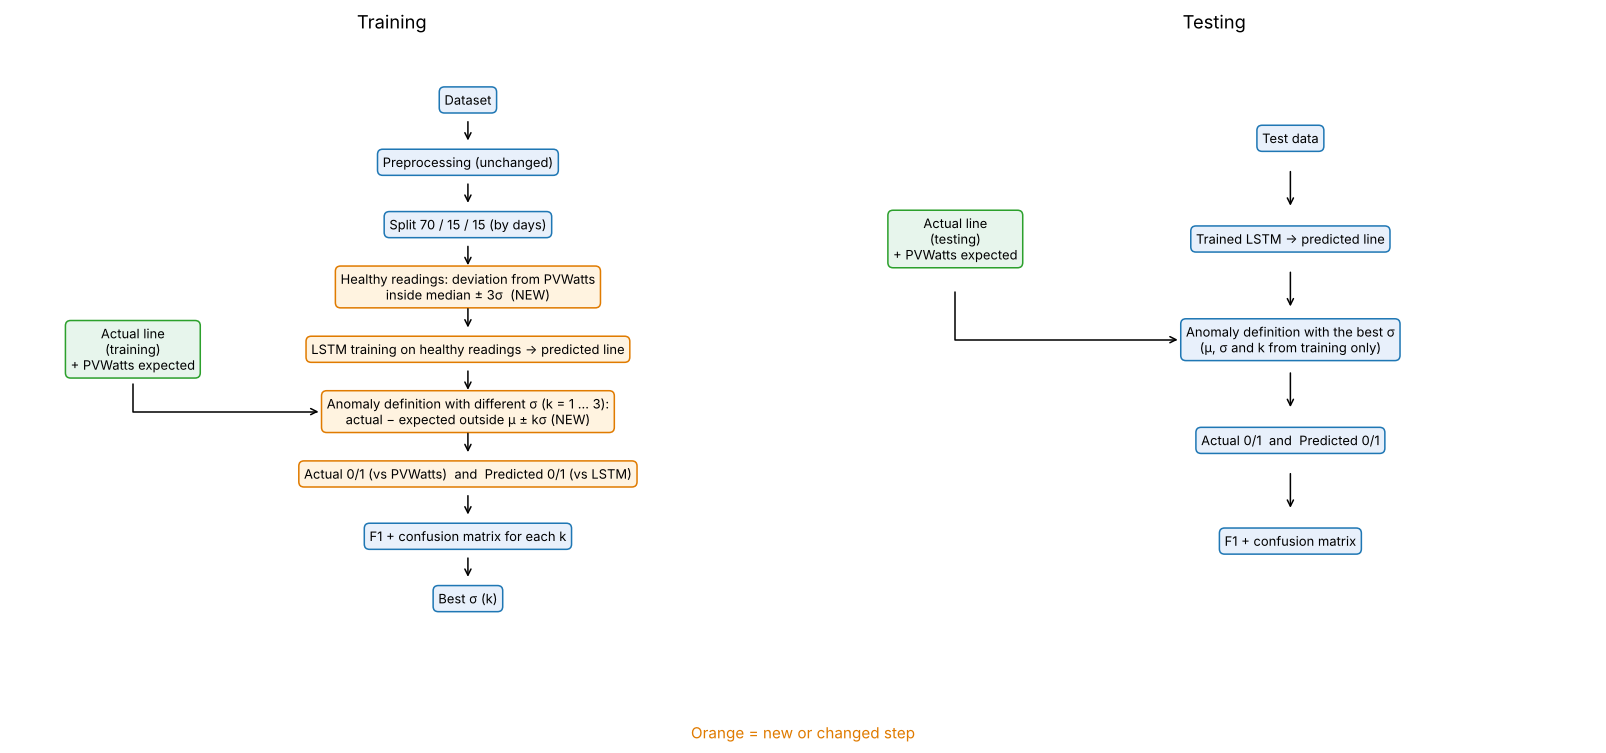

In [11]:
# Cell 10 — Plot 6: workflow (Dr. Mai's sketches: training and testing), with the new steps
def draw_flow(ax, title, main, side_box, tail, new=()):
    ax.set_xlim(0, 10); ax.set_ylim(0, len(main) + len(tail) + 1.5); ax.axis('off'); ax.set_title(title, fontsize=12)
    y = len(main) + len(tail) + 0.5
    box = dict(boxstyle='round,pad=0.4', fc='#e8f0fb', ec='#1f77b4')
    box_new = dict(boxstyle='round,pad=0.4', fc='#fff3e0', ec='#e07b00')
    pos, txt = {}, {}
    for t in main + tail:
        txt[t] = ax.text(6, y, t, ha='center', va='center', bbox=box_new if t in new else box, fontsize=8.5); pos[t] = y; y -= 1
    ys = pos[main[-1]]
    ax.text(1.6, ys, side_box, ha='center', va='center', bbox=dict(boxstyle='round,pad=0.4', fc='#e7f5ec', ec='#2ca02c'), fontsize=8.5)
    order = main + tail
    for a, b in zip(order, order[1:]):
        ax.annotate('', (6, pos[b] + 0.3), (6, pos[a] - 0.3), arrowprops=dict(arrowstyle='->'))
    ax.figure.canvas.draw()
    x_left = txt[tail[0]].get_bbox_patch().get_window_extent().transformed(ax.transData.inverted()).x0
    ax.annotate('', (x_left, pos[tail[0]]), (1.6, ys - 0.5), arrowprops=dict(arrowstyle='->', connectionstyle='angle,angleA=-90,angleB=180'))

tr_main = ['Dataset', 'Preprocessing (unchanged)', 'Split 70 / 15 / 15 (by days)',
           'Healthy readings: deviation from PVWatts\ninside median ± 3σ  (NEW)',
           'LSTM training on healthy readings → predicted line']
tr_tail = ['Anomaly definition with different σ (k = 1 … 3):\nactual − expected outside μ ± kσ (NEW)',
           'Actual 0/1 (vs PVWatts)  and  Predicted 0/1 (vs LSTM)', 'F1 + confusion matrix for each k', 'Best σ (k)']
te_main = ['Test data', 'Trained LSTM → predicted line']
te_tail = ['Anomaly definition with the best σ\n(μ, σ and k from training only)', 'Actual 0/1  and  Predicted 0/1', 'F1 + confusion matrix']
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
fig.subplots_adjust(left=0.02, right=0.98, top=0.93, bottom=0.08, wspace=0.08)   # fixed layout, so the arrows end at the boxes
draw_flow(axes[0], 'Training', tr_main, 'Actual line\n(training)\n+ PVWatts expected', tr_tail,
          new={tr_main[3], tr_main[4], tr_tail[0], tr_tail[1]})
draw_flow(axes[1], 'Testing', te_main, 'Actual line\n(testing)\n+ PVWatts expected', te_tail)
fig.text(0.5, 0.02, 'Orange = new or changed step', ha='center', color='#e07b00')
fig.savefig(os.path.join(PLOT_DIR, '6_workflow.png'), dpi=150); plt.show()

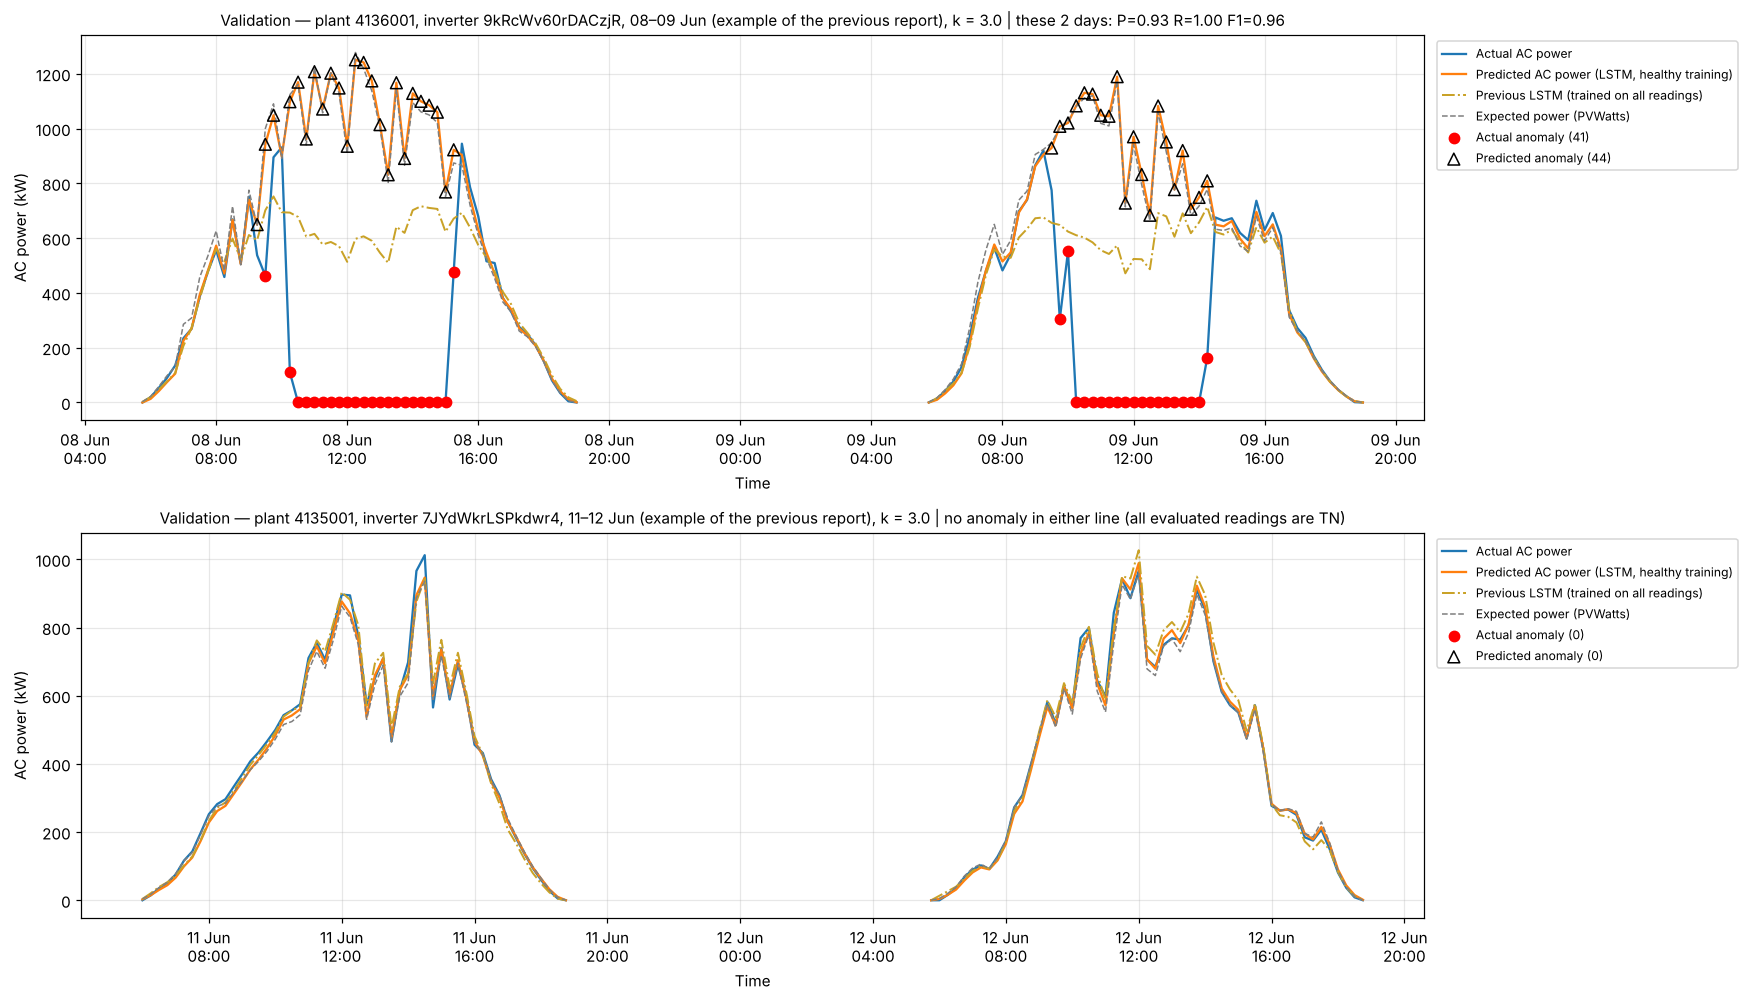

In [12]:
# Cell 10b — Plot 8 (NEW): the example days of the previous report, with the new method
#   Top: plant 4136001, inverter 9kRcWv60rDACzjR, 8–9 June — outages from about 10:30 to 15:00 (were FN before)
#   Bottom: plant 4135001, inverter 7JYdWkrLSPkdwr4, 11–12 June — cloudy morning (was flagged as an anomaly before)
examples = [('val', '9kRcWv60rDACzjR', '2020-06-08'), ('val', '7JYdWkrLSPkdwr4', '2020-06-11')]
fig, axes = plt.subplots(len(examples), 1, figsize=(16, 4.6 * len(examples)))
for ax, (s, inv, day) in zip(axes, examples):
    if inv not in set(data[s]['SOURCE_KEY']):
        ax.set_visible(False); continue
    start = pd.Timestamp(day); end = start + pd.Timedelta(days=2)
    w = window(data[s], inv, start, end)
    plant = int(data[s].loc[data[s]['SOURCE_KEY'] == inv, 'PLANT_ID'].iloc[0])
    res = result_column(data[s][(data[s]['SOURCE_KEY'] == inv) & (data[s]['DATE_TIME'] >= start) & (data[s]['DATE_TIME'] < end)], K, MAIN)
    P, R, F = scores(res)
    score_txt = (f'these 2 days: P={P:.2f} R={R:.2f} F1={F:.2f}' if (res != 'TN').sum() - (res == 'not evaluated').sum()
                 else 'no anomaly in either line (all evaluated readings are TN)')
    draw_panel(ax, w, f'{NAMES[s]} — plant {plant}, inverter {inv}, {start:%d}–{(end - pd.Timedelta(days=1)):%d %b} '
                      f'(example of the previous report), k = {K} | {score_txt}', show_old=True)
fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, '8_previous_report_examples_new_method.png'), dpi=150); plt.show()

In [13]:
# Cell 11 — The six final files (main version, best k), with the 3 weather inputs + counts table
INPUTS = ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']
key = ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY']
power = ['ACTUAL_AC_POWER_kW', 'PREDICTED_AC_POWER_kW', 'EXPECTED_PHYS_kW']
names = {'train': ('1_LSTM_Training_Output_Prediction.csv',   '2_LSTM_Training_Output_Thresholding.csv'),
         'val':   ('3_LSTM_Validation_Output_Prediction.csv', '4_LSTM_Validation_Output_Thresholding.csv'),
         'test':  ('5_LSTM_Testing_Output_Prediction.csv',    '6_LSTM_Testing_Output_Anomaly.csv')}
for s in SPLITS:
    d = data[s]
    d[key + INPUTS + power].to_csv(os.path.join(FINAL_DIR, names[s][0]), index=False)       # prediction file
    out = d[key + INPUTS + power].copy()
    out['k'] = K
    out['EVALUATED'] = d['EVALUATED'].values
    out['actual_minus_expected_kW'] = d['RESID_ACTUAL_kW'].round(2).values
    out['actual_minus_predicted_kW'] = d['RESID_PRED_kW'].round(2).values
    out['actual_anomaly'] = d[f'actual_anomaly_k{K}'].values
    out['predicted_anomaly'] = d[f'pred_anomaly_k{K}'].values
    out['result'] = result_column(d, K, MAIN)
    out.to_csv(os.path.join(FINAL_DIR, names[s][1]), index=False)

check = pd.DataFrame({s: {'rows': len(data[s]), 'evaluated rows': int(data[s]['EVALUATED'].sum()),
                          'actual anomalies': int(data[s][f'actual_anomaly_k{K}'].sum()),
                          'predicted anomalies': int(data[s][f'pred_anomaly_k{K}'].sum())} for s in SPLITS}).T
check = check.rename(index=NAMES)
check.index.name = 'Split'
check.to_csv(os.path.join(OUT_DIR, 'counts_per_split.csv'))
print(f'{VERSION_TXT[MAIN]}, k = {K}')
print(sorted(os.listdir(FINAL_DIR)))
check

Version A (plain 0/1), k = 3.0
['1_LSTM_Training_Output_Prediction.csv', '2_LSTM_Training_Output_Thresholding.csv', '3_LSTM_Validation_Output_Prediction.csv', '4_LSTM_Validation_Output_Thresholding.csv', '5_LSTM_Testing_Output_Prediction.csv', '6_LSTM_Testing_Output_Anomaly.csv']


,rows,evaluated rows,actual anomalies,predicted anomalies
Split,,,,
Training,36491,24170,3481,4076
Validation,11968,7458,827,1070
Testing,10758,6930,812,936


In [14]:
# Cell 12 — Zip and download everything (6 files + plots + summary + counts table)
zip_path = shutil.make_archive(os.path.join(OUTPUTS, 'final_outputs'), 'zip', OUT_DIR)
for root, _, fs in os.walk(OUT_DIR):
    for f in sorted(fs):
        print(os.path.relpath(os.path.join(root, f), OUT_DIR))
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('Saved to', zip_path)

counts_per_split.csv
final_results_summary.csv
metrics_per_inverter.csv
plots/1_actual_vs_predicted_test.png
plots/1_actual_vs_predicted_train.png
plots/1_actual_vs_predicted_val.png
plots/2_anomaly_calculation_test_plant_4135001.png
plots/2_anomaly_calculation_test_plant_4136001.png
plots/2_anomaly_calculation_train_plant_4135001.png
plots/2_anomaly_calculation_train_plant_4136001.png
plots/2_anomaly_calculation_val_plant_4135001.png
plots/2_anomaly_calculation_val_plant_4136001.png
plots/3_actual_vs_predicted_vectors.png
plots/4_f1_vs_k_and_final_scores.png
plots/5_confusion_matrices_best_k.png
plots/6_workflow.png
plots/7a_f1_every_inverter.png
plots/7b_all_inverters_test.png
plots/7b_all_inverters_train.png
plots/7b_all_inverters_val.png
plots/8_previous_report_examples_new_method.png
final_files/1_LSTM_Training_Output_Prediction.csv
final_files/2_LSTM_Training_Output_Thresholding.csv
final_files/3_LSTM_Validation_Output_Prediction.csv
final_files/4_LSTM_Validation_Output_Threshold